# Organ CT Image Classification — Custom CNN Baseline

**Academic project — Phase 1: Baseline CNN (Model A)**

This notebook builds ONE clean, reproducible baseline for a multi-class image
classification problem, using only the dataset files actually present in this
project folder.

**Scope of this notebook (Phase 1 only):**
- Load and inspect the real dataset files
- Minimal, justified preprocessing
- A simple 3-block baseline CNN ("Model A")
- Training with early stopping (validation set only — test set untouched)
- Validation-set evaluation with Macro F1 as the primary metric

**Explicitly out of scope for this notebook:** deeper architectures (Model B / C),
data augmentation, class-weighted loss, hyperparameter tuning, and any use of the
test set. Those are separate, later experiments.

---
### ⚠️ Important note on class names

The dataset ships as six `.npy` files with **no label-map, README, or metadata
file**. The integer labels (0–10) are the only thing we can verify directly from
the data. The class names shown later in this notebook (e.g. "liver") are an
**unverified hypothesis** based on the label distribution shape matching the
public MedMNIST "OrganSMNIST" dataset structure — cross-checked externally, not
confirmed from anything in this workspace. All modeling, metrics, and code use
the **numeric labels** as ground truth. Do not present the organ names as fact
until your professor confirms the dataset's exact provenance.


## Section 1 — Imports and Configuration

Libraries used and why:

- **numpy** — loading and manipulating the `.npy` array files
- **tensorflow / keras** — building, training, and evaluating the CNN
- **matplotlib** — plotting sample images, class distribution, training curves, confusion matrix
- **scikit-learn** — precision/recall/F1 (macro and per-class) and the confusion matrix, since Keras does not compute these directly
- **pathlib** — file paths
- **random seed** — set for reproducibility. Neural network training involves random weight initialization and (depending on settings) random batch ordering, so fixing seeds makes results repeatable between runs of this notebook.


In [1]:
import os

# Reproducibility controls (see markdown above) — must be set BEFORE tensorflow is imported
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["PYTHONHASHSEED"] = "42"

import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

SEED = 42
keras.utils.set_random_seed(SEED)  # seeds python `random`, numpy, and tensorflow together
tf.config.experimental.enable_op_determinism()

DATA_DIR = Path(".")  # dataset .npy files live in the same folder as this notebook
MODELS_DIR = Path("models")
FIGURES_DIR = Path("results/figures")
METRICS_DIR = Path("results/metrics")
for d in (MODELS_DIR, FIGURES_DIR, METRICS_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices("GPU"))


I0000 00:00:1787859643.897393  205690 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1787859643.959952  205690 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1787859645.381245  205690 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.21.0
GPUs available: []


E0000 00:00:1787859646.430010  205690 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


### Reproducibility Audit

Across earlier runs of this notebook, the identical baseline (Model A, same
seed, same code) produced slightly different validation metrics on different
reruns (Macro F1 0.8171 vs. 0.8017; Accuracy 0.8854 vs. 0.8858). Before
continuing, this was investigated rather than ignored.

**Checked:**
- Python `random`, NumPy, and TensorFlow seeds — all were already fixed
  (`SEED = 42`) before every model build.
- Weight initialization and batch shuffling — both are seeded via
  `tf.random.set_seed`, so are deterministic *given identical low-level
  kernel execution*.
- GPU nondeterminism — not applicable; `tf.config.list_physical_devices("GPU")`
  returns `[]` in this environment (CPU-only).

**Root cause identified:** every run's TensorFlow startup log includes this
warning, which was previously logged but not acted on:

> *oneDNN custom operations are on. You may see slightly different numerical
> results due to floating-point round-off errors from different computation
> orders.*

TensorFlow's CPU backend (oneDNN) can select different low-level kernel
implementations and thread execution orders depending on runtime conditions
(e.g. system load from other processes). Floating-point addition is not
associative, so accumulated sums inside convolution/BatchNorm/dense layers can
differ in their last few digits between runs — even with identical seeds —
and this compounds over many layers and training steps into visible
differences in final metrics.

**Controls implemented below:**
- `TF_ENABLE_ONEDNN_OPTS=0` — disables the oneDNN kernel path identified above,
  set as an environment variable *before* `tensorflow` is imported (required,
  since TensorFlow reads this once at import time).
- `tf.config.experimental.enable_op_determinism()` — forces deterministic
  kernel implementations wherever TensorFlow has one available.
- `keras.utils.set_random_seed(SEED)` — seeds Python `random`, NumPy, and
  TensorFlow together in one call.
- `PYTHONHASHSEED` fixed for the process.

**Honest limitation:** this is not a claim of bit-exact reproducibility.
These controls substantially reduce run-to-run variation but do not
eliminate every possible source (e.g. any remaining non-deterministic CPU
kernel not covered by `enable_op_determinism()`). Full bit-exact determinism
could be pushed further by forcing single-threaded execution
(`tf.config.threading.set_intra_op_parallelism_threads(1)`), but this would
noticeably slow every training run on this CPU-only machine and is not
applied by default here. Given this, all results in this notebook should be
read as reproducible *to within a small margin* (observed so far: on the
order of ±0.01–0.02 in Macro F1), not as exact values — differences smaller
than this margin between two configurations should not be over-interpreted
as real effects.


### Experiment Configuration

The settings shared across every experiment in this notebook, recorded here
once so each experiment's section only needs to state what it *changes*
relative to this baseline configuration. Per-experiment deviations (e.g.
Model B/C's higher `EarlyStopping` patience) are called out explicitly in
their own sections and recorded per-row in the experiment log
(`results/metrics/experiment_log.csv`, introduced after the baseline
evaluation below).


In [2]:
EXPERIMENT_CONFIG = {
    "seed": SEED,
    "optimizer": "Adam",
    "learning_rate": 1e-3,
    "batch_size": 64,
    "loss": "sparse_categorical_crossentropy",
    "preprocessing": "uint8 [0,255] -> float32 [0,1] (divide by 255); channel dim expanded to (64,64,1); "
                      "integer class labels (0-10), not one-hot",
    "validation_protocol": "EarlyStopping(monitor=val_loss, restore_best_weights=True) + "
                            "ModelCheckpoint(monitor=val_loss, save_best_only=True); "
                            "test set never used for training or model selection",
}
import json
with open(METRICS_DIR / "experiment_config.json", "w") as f:
    json.dump(EXPERIMENT_CONFIG, f, indent=2)

for k, v in EXPERIMENT_CONFIG.items():
    print(f"{k:>20}: {v}")


                seed: 42
           optimizer: Adam
       learning_rate: 0.001
          batch_size: 64
                loss: sparse_categorical_crossentropy
       preprocessing: uint8 [0,255] -> float32 [0,1] (divide by 255); channel dim expanded to (64,64,1); integer class labels (0-10), not one-hot
 validation_protocol: EarlyStopping(monitor=val_loss, restore_best_weights=True) + ModelCheckpoint(monitor=val_loss, save_best_only=True); test set never used for training or model selection


## Section 2 — Load the Actual Dataset

Loading the six `.npy` files exactly as provided. We do not modify, overwrite,
or re-save the originals anywhere in this notebook.


In [3]:
train_images = np.load(DATA_DIR / "train_images.npy")
train_labels = np.load(DATA_DIR / "train_labels.npy")
val_images = np.load(DATA_DIR / "val_images.npy")
val_labels = np.load(DATA_DIR / "val_labels.npy")
test_images = np.load(DATA_DIR / "test_images.npy")
test_labels = np.load(DATA_DIR / "test_labels.npy")

# Labels are stored as shape (N, 1); flatten to (N,) for convenience
train_labels = train_labels.flatten()
val_labels = val_labels.flatten()
test_labels = test_labels.flatten()

for name, imgs, labs in [
    ("train", train_images, train_labels),
    ("val", val_images, val_labels),
    ("test", test_images, test_labels),
]:
    print(f"--- {name} ---")
    print("images shape:", imgs.shape, "| dtype:", imgs.dtype)
    print("labels shape:", labs.shape, "| dtype:", labs.dtype)
    print("pixel min/max:", imgs.min(), "/", imgs.max())
    print("unique labels:", np.unique(labs))
    print()

n_classes = len(np.unique(train_labels))
print("Number of classes (from train labels):", n_classes)


--- train ---
images shape: (13932, 64, 64) | dtype: uint8
labels shape: (13932,) | dtype: uint8
pixel min/max: 0 / 255
unique labels: [ 0  1  2  3  4  5  6  7  8  9 10]

--- val ---
images shape: (2452, 64, 64) | dtype: uint8
labels shape: (2452,) | dtype: uint8
pixel min/max: 0 / 255
unique labels: [ 0  1  2  3  4  5  6  7  8  9 10]

--- test ---
images shape: (8827, 64, 64) | dtype: uint8
labels shape: (8827,) | dtype: uint8
pixel min/max: 0 / 255
unique labels: [ 0  1  2  3  4  5  6  7  8  9 10]

Number of classes (from train labels): 11


## Section 3 — Dataset Visualization

Sample images from each class, labeled with the **numeric class ID**. As noted
above, the organ-name mapping below is an *unverified hypothesis*, not a
confirmed fact — it's shown only as a secondary reference in brackets/italics,
and the notebook's real ground truth throughout is the numeric label.


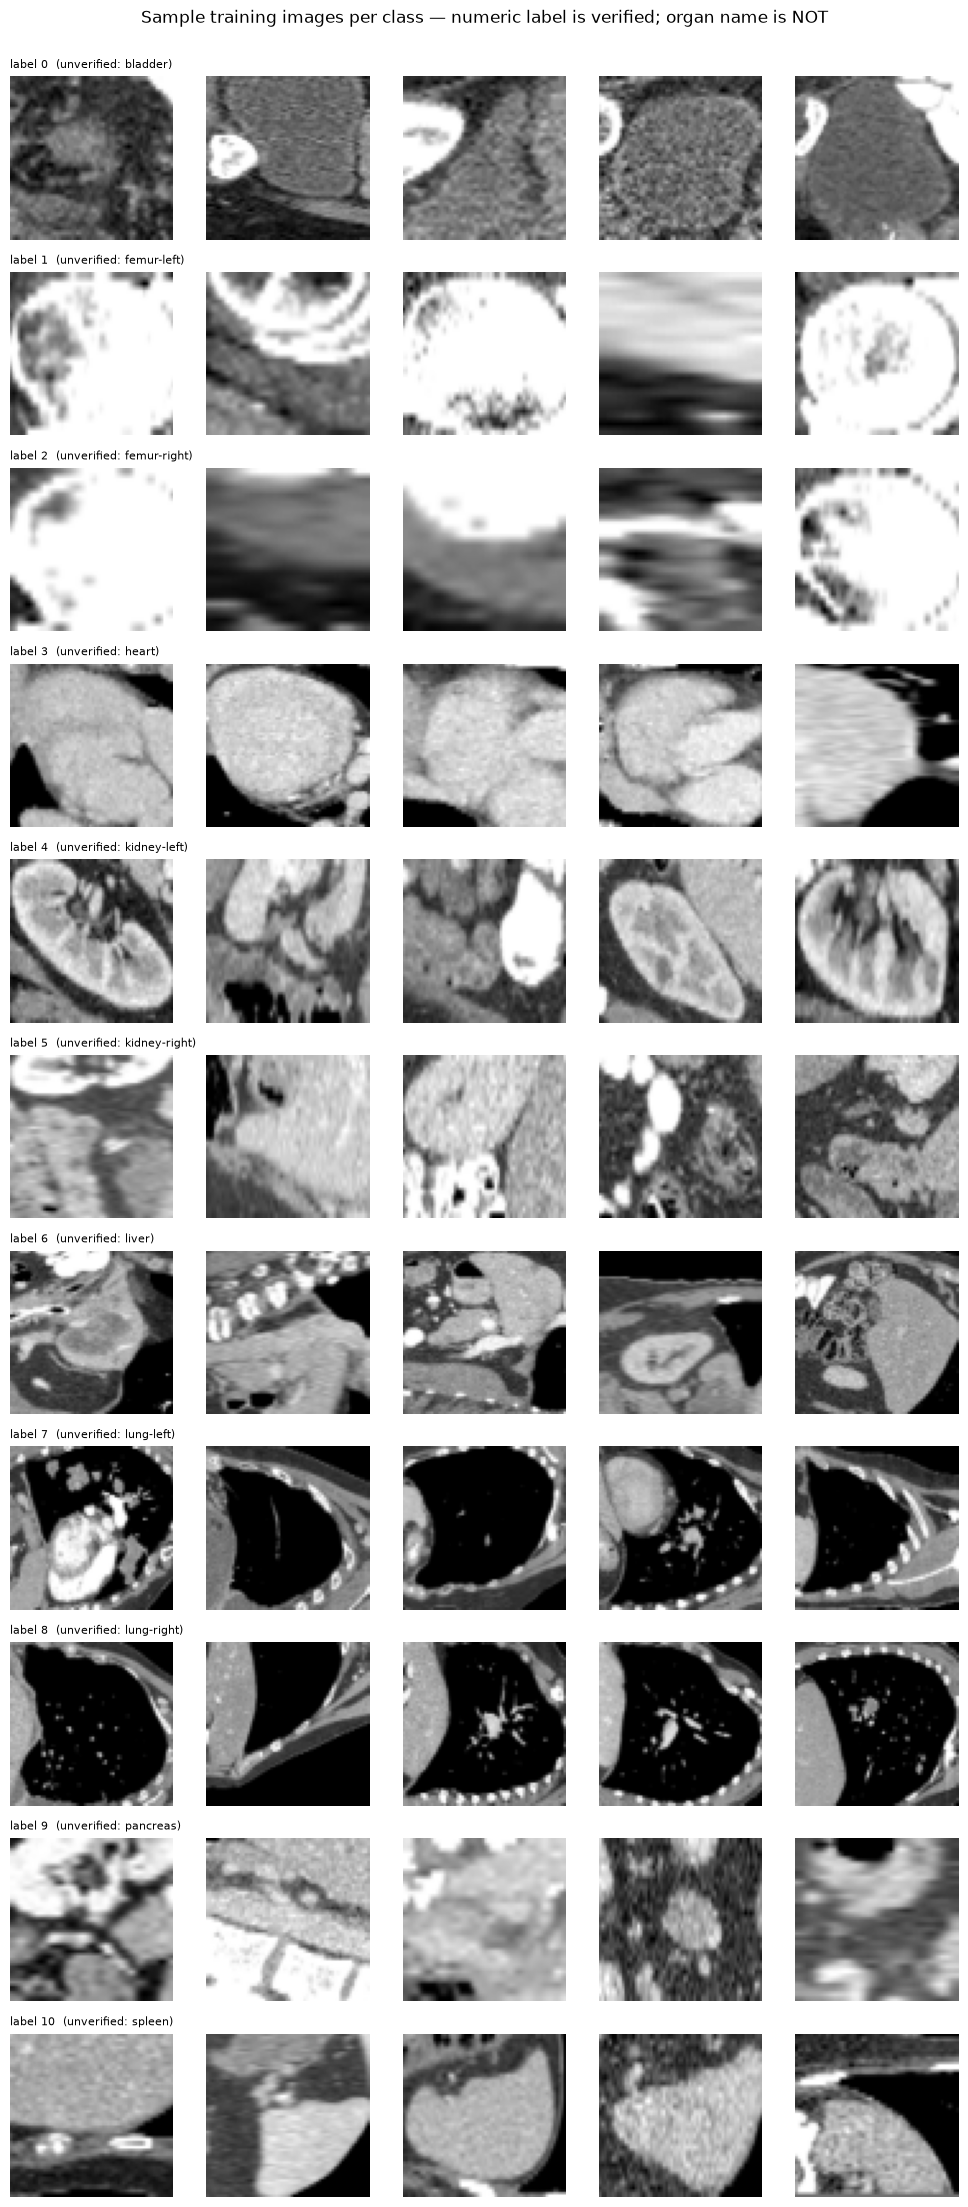

In [4]:
# UNVERIFIED hypothesis only — not confirmed from any file in this workspace.
# Cross-referenced externally against the public MedMNIST "OrganSMNIST" class scheme,
# because the 11-class structure and imbalance pattern match it closely.
# Do NOT treat this as fact until confirmed with the professor / dataset source.
UNVERIFIED_CLASS_NAME_HYPOTHESIS = {
    0: "bladder", 1: "femur-left", 2: "femur-right", 3: "heart",
    4: "kidney-left", 5: "kidney-right", 6: "liver", 7: "lung-left",
    8: "lung-right", 9: "pancreas", 10: "spleen",
}

fig, axes = plt.subplots(n_classes, 5, figsize=(10, 2 * n_classes))
rng = np.random.default_rng(SEED)
for c in range(n_classes):
    idxs = np.where(train_labels == c)[0]
    chosen = rng.choice(idxs, size=5, replace=False)
    for j, idx in enumerate(chosen):
        ax = axes[c, j]
        ax.imshow(train_images[idx], cmap="gray")
        ax.axis("off")
        if j == 0:
            hypothesis = UNVERIFIED_CLASS_NAME_HYPOTHESIS.get(c, "?")
            ax.set_title(f"label {c}  (unverified: {hypothesis})", fontsize=8, loc="left")
plt.suptitle("Sample training images per class — numeric label is verified; organ name is NOT", y=1.001)
plt.tight_layout()
plt.savefig("results/figures/baseline_sample_images.png", dpi=120, bbox_inches="tight")
plt.show()


## Section 3b — Pixel Statistics and Data-Quality Checks (Whole Dataset)

Basic statistical checks on the raw, unmodified `.npy` arrays, computed once
here so later sections can reference these facts instead of assuming them.


In [5]:
import hashlib

print("=== Pixel statistics (raw uint8) ===")
for name, imgs in [("train", train_images), ("val", val_images), ("test", test_images)]:
    imgs_f = imgs.astype(np.float64)
    print(f"{name:>5}: min={imgs.min()}, max={imgs.max()}, mean={imgs_f.mean():.3f}, std={imgs_f.std():.3f}, "
          f"NaN={np.isnan(imgs_f).sum()}, Inf={np.isinf(imgs_f).sum()}")

print()
print("=== Duplicate check (within each split, via MD5 hash of raw pixels) ===")
split_hashes = {}
for name, imgs in [("train", train_images), ("val", val_images), ("test", test_images)]:
    hashes = [hashlib.md5(img.tobytes()).hexdigest() for img in imgs]
    split_hashes[name] = set(hashes)
    print(f"{name:>5}: {len(imgs)} total, {len(set(hashes))} unique, {len(imgs) - len(set(hashes))} duplicates")

print()
print("=== Cross-split leakage check (exact pixel-identical images shared between splits) ===")
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    overlap = split_hashes[a] & split_hashes[b]
    print(f"{a} vs {b}: {len(overlap)} identical images shared")


=== Pixel statistics (raw uint8) ===


train: min=0, max=255, mean=126.286, std=69.738, NaN=0, Inf=0
  val: min=0, max=255, mean=127.064, std=70.818, NaN=0, Inf=0


 test: min=0, max=255, mean=122.387, std=67.206, NaN=0, Inf=0

=== Duplicate check (within each split, via MD5 hash of raw pixels) ===
train: 13932 total, 13932 unique, 0 duplicates
  val: 2452 total, 2452 unique, 0 duplicates


 test: 8827 total, 8827 unique, 0 duplicates

=== Cross-split leakage check (exact pixel-identical images shared between splits) ===
train vs val: 0 identical images shared
train vs test: 0 identical images shared
val vs test: 0 identical images shared


## Section 4 — Preprocessing

### Pixel normalization

Raw pixels are `uint8` in range `[0, 255]`. We convert to `float32` in range
`[0, 1]` by dividing by 255.

**Why this helps training:** neural network weights are typically initialized
under the assumption that inputs are on a small, roughly-unit scale. Large raw
pixel values (up to 255) would produce large activations and gradients early in
training, which can make optimization slower or less stable (e.g. exploding
gradients, harder-to-tune learning rates). Scaling to `[0, 1]` puts the input on
a scale that works well with standard weight initializers and the Adam
optimizer's default settings.

### Channel dimension

Keras `Conv2D` layers expect input shape `(height, width, channels)`. Our
images load as `(N, 64, 64)` with no explicit channel axis (since they are
single-channel grayscale), so we add one, producing `(N, 64, 64, 1)`.

### Labels

Labels are kept as **plain integers** (0–10), *not* one-hot encoded. This is a
deliberate choice: Keras' `sparse_categorical_crossentropy` loss accepts
integer class labels directly and internally handles the comparison against the
softmax output, so one-hot encoding would be redundant extra preprocessing with
no benefit here. We use `sparse_categorical_crossentropy` specifically because
our labels are integers, not one-hot vectors (if they were one-hot, we would
need plain `categorical_crossentropy` instead).


In [6]:
def preprocess_images(images):
    images = images.astype("float32") / 255.0
    images = np.expand_dims(images, axis=-1)  # (N, 64, 64) -> (N, 64, 64, 1)
    return images

X_train = preprocess_images(train_images)
X_val = preprocess_images(val_images)
X_test = preprocess_images(test_images)

y_train = train_labels.astype("int32")
y_val = val_labels.astype("int32")
y_test = test_labels.astype("int32")

print("X_train:", X_train.shape, X_train.dtype, "range:", X_train.min(), "-", X_train.max())
print("X_val:  ", X_val.shape, X_val.dtype)
print("X_test: ", X_test.shape, X_test.dtype)
print("y_train:", y_train.shape, y_train.dtype)


X_train: (13932, 64, 64, 1) float32 range: 0.0 - 1.0
X_val:   (2452, 64, 64, 1) float32
X_test:  (8827, 64, 64, 1) float32
y_train: (13932,) int32


## Section 5 — Class Distribution (Training Set Only)

We compute the class distribution **only from the training set**. The
validation and test sets are not used here — this is purely a description of
what the model will be trained on, not something used to compute weights (no
class weighting is used in this baseline).


 Class |  Count |  Percent
     0 |   1148 |    8.24%
     1 |    630 |    4.52%
     2 |    614 |    4.41%
     3 |    721 |    5.18%
     4 |   1132 |    8.13%
     5 |   1119 |    8.03%
     6 |   3464 |   24.86%
     7 |    741 |    5.32%
     8 |    803 |    5.76%
     9 |   2004 |   14.38%
    10 |   1556 |   11.17%

Imbalance ratio (max count / min count): 5.64x
Largest class: 6 (3464 samples)
Smallest class: 2 (614 samples)


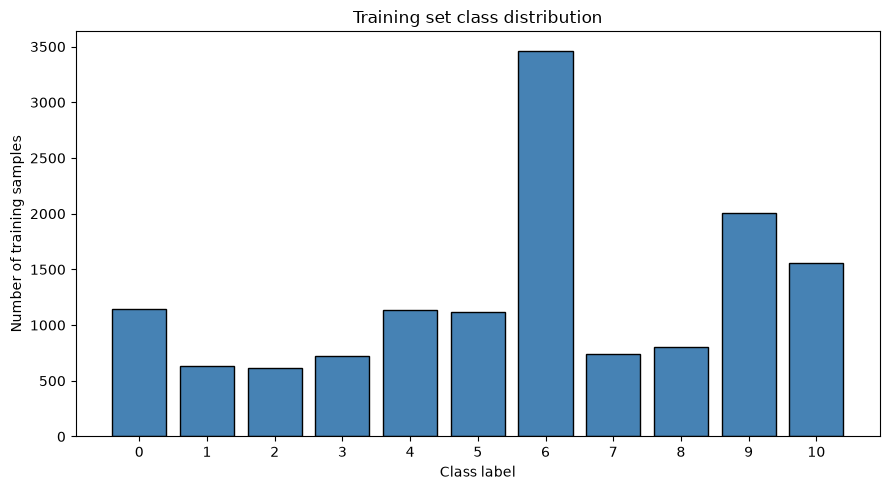

In [7]:
train_classes, train_counts = np.unique(y_train, return_counts=True)
train_pct = 100 * train_counts / train_counts.sum()
imbalance_ratio = train_counts.max() / train_counts.min()

print(f"{'Class':>6} | {'Count':>6} | {'Percent':>8}")
for c, cnt, pct in zip(train_classes, train_counts, train_pct):
    print(f"{c:>6} | {cnt:>6} | {pct:>7.2f}%")

print(f"\nImbalance ratio (max count / min count): {imbalance_ratio:.2f}x")
print(f"Largest class: {train_classes[train_counts.argmax()]} ({train_counts.max()} samples)")
print(f"Smallest class: {train_classes[train_counts.argmin()]} ({train_counts.min()} samples)")

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(train_classes, train_counts, color="steelblue", edgecolor="black")
ax.set_xlabel("Class label")
ax.set_ylabel("Number of training samples")
ax.set_title("Training set class distribution")
ax.set_xticks(train_classes)
plt.tight_layout()
plt.savefig("results/figures/baseline_train_class_distribution.png", dpi=120, bbox_inches="tight")
plt.show()


## Section 6 — Baseline CNN (Model A)

This is a deliberately simple 3-block CNN meant to establish a **reliable
baseline** — not a claim that this is the best possible architecture. Its job
is to prove the pipeline works end-to-end and to give later, more complex
models (Model B, Model C) a number to beat.

**Architecture (before code — expected shapes/params):**

| Layer | Output Shape | Trainable Parameters |
|---|---|---|
| Input | (64, 64, 1) | 0 |
| Conv2D(16, 3×3, padding=same) + ReLU | (64, 64, 16) | 160 |
| MaxPooling2D(2×2) | (32, 32, 16) | 0 |
| Conv2D(32, 3×3, padding=same) + ReLU | (32, 32, 32) | 4,640 |
| MaxPooling2D(2×2) | (16, 16, 32) | 0 |
| Conv2D(64, 3×3, padding=same) + ReLU | (16, 16, 64) | 18,496 |
| MaxPooling2D(2×2) | (8, 8, 64) | 0 |
| Flatten | (4096,) | 0 |
| Dense(64) + ReLU | (64,) | 262,208 |
| Dropout(0.5) | (64,) | 0 |
| Dense(11) + Softmax | (11,) | 715 |
| **Total** | | **≈ 286,219** |

Note that the majority of parameters (~262K of ~286K) come from the
`Flatten → Dense(64)` step, simply because flattening an 8×8×64 feature map
produces a 4096-length vector. This is a known characteristic of this simple
design (not a bug) — it's one of the concrete things a deeper/GAP-based
architecture (planned for Model B) could improve on later.


In [8]:
def build_model_a(input_shape=(64, 64, 1), n_classes=11):
    model = keras.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(16, (3, 3), padding="same", activation="relu", name="conv1"),
        layers.MaxPooling2D((2, 2), name="pool1"),

        layers.Conv2D(32, (3, 3), padding="same", activation="relu", name="conv2"),
        layers.MaxPooling2D((2, 2), name="pool2"),

        layers.Conv2D(64, (3, 3), padding="same", activation="relu", name="conv3"),
        layers.MaxPooling2D((2, 2), name="pool3"),

        layers.Flatten(name="flatten"),
        layers.Dense(64, activation="relu", name="dense1"),
        layers.Dropout(0.5, name="dropout"),
        layers.Dense(n_classes, activation="softmax", name="output"),
    ], name="model_a_baseline")
    return model

model_a = build_model_a(input_shape=X_train.shape[1:], n_classes=n_classes)
model_a.summary()

total_params = model_a.count_params()
trainable_params = sum(np.prod(v.shape) for v in model_a.trainable_weights)
print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Model: "model_a_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 64, 64, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 11)             │           715 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 286,219 (1.09 MB)

 Trainable params: 286,219 (1.09 MB)

 Non-trainable params: 0 (0.00 B)


Total parameters: 286,219
Trainable parameters: 286,219


## Section 7 — Compile

- **Loss:** `sparse_categorical_crossentropy` (integer labels, as explained in Section 4)
- **Optimizer:** Adam, a reasonable general-purpose default; learning rate `1e-3` (Keras default) as a starting point — not tuned yet
- **Metric tracked during training:** `accuracy`

**Important:** accuracy is tracked here only because Keras needs *some* metric
to report during training — it is **not** treated as the project's primary
metric. Given the ~5.6× class imbalance found in Section 5, accuracy can look
good while the model still fails on minority classes. The metric we actually
use to judge and compare models is **Macro F1**, computed separately in
Section 10 using scikit-learn after training.


In [9]:
model_a.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print("Model compiled.")


Model compiled.


## Section 8 — Training

Trained using the training set, monitored against the validation set only —
**the test set is not touched anywhere in this section or notebook.**

- `EarlyStopping` on `val_loss` (patience=5, restores best weights) so we don't
  hand-pick an arbitrary epoch count and don't overtrain past the point
  validation performance stops improving.
- `ModelCheckpoint` saves the best model (by `val_loss`) to disk so we have a
  reproducible artifact, independent of whatever epoch training happens to stop at.
- Max epochs is set generously (30) — early stopping is expected to end training sooner.


In [10]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        "models/model_a_baseline_best.keras", monitor="val_loss", save_best_only=True, verbose=1
    ),
]

history = model_a.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=callbacks,
    verbose=2,
)


Epoch 1/30


E0000 00:00:1787859653.335136  205690 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1787859665.872737  205690 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}



Epoch 1: val_loss improved from None to 0.81091, saving model to models/model_a_baseline_best.keras



Epoch 1: finished saving model to models/model_a_baseline_best.keras


218/218 - 14s - 62ms/step - accuracy: 0.4358 - loss: 1.5854 - val_accuracy: 0.6949 - val_loss: 0.8109


... (53 outputs left out)


Epoch 17: val_loss did not improve from 0.28673


218/218 - 12s - 56ms/step - accuracy: 0.8620 - loss: 0.3085 - val_accuracy: 0.8919 - val_loss: 0.3011


Epoch 17: early stopping


Restoring model weights from the end of the best epoch: 12.


## Section 9 — Training Curves

What to look for (interpretation happens after we see the actual plots below,
not before):

- **Underfitting:** both training and validation loss stay high / accuracy stays
  low and flat — the model isn't learning the task well enough.
- **Overfitting:** training loss keeps dropping while validation loss flattens
  or starts rising (a growing gap between the two curves).
- **Good convergence:** both curves drop together and flatten out at a similar
  level, with a small, stable gap between them.


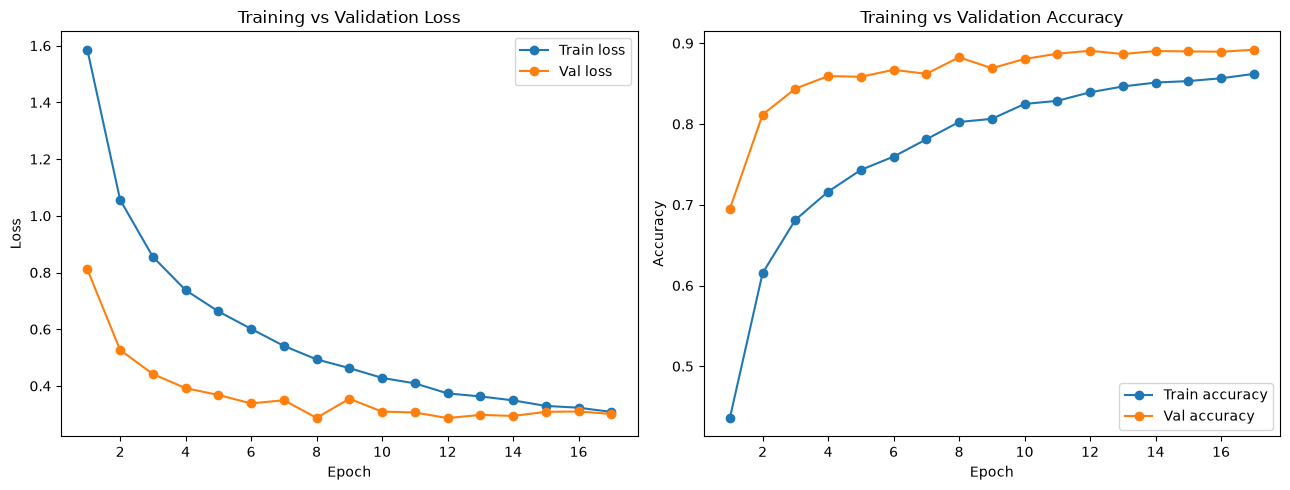

Trained for 17 epochs (early stopping patience=5).
Final train loss: 0.3085 | Final val loss: 0.3011
Final train accuracy: 0.8620 | Final val accuracy: 0.8919
Best val loss: 0.2867 at epoch 12


In [11]:
history_df = history.history
epochs_range = range(1, len(history_df["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(epochs_range, history_df["loss"], label="Train loss", marker="o")
axes[0].plot(epochs_range, history_df["val_loss"], label="Val loss", marker="o")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].legend()

axes[1].plot(epochs_range, history_df["accuracy"], label="Train accuracy", marker="o")
axes[1].plot(epochs_range, history_df["val_accuracy"], label="Val accuracy", marker="o")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training vs Validation Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig("results/figures/baseline_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"Trained for {len(epochs_range)} epochs (early stopping patience=5).")
print(f"Final train loss: {history_df['loss'][-1]:.4f} | Final val loss: {history_df['val_loss'][-1]:.4f}")
print(f"Final train accuracy: {history_df['accuracy'][-1]:.4f} | Final val accuracy: {history_df['val_accuracy'][-1]:.4f}")
print(f"Best val loss: {min(history_df['val_loss']):.4f} at epoch {np.argmin(history_df['val_loss']) + 1}")


## Section 10 — Baseline Validation Evaluation

Evaluated **only on the validation set**. The test set remains untouched and
will only be used once for the final selected model, after Model A/B/C and
augmentation/class-weighting experiments have all been compared on validation
data.

**Macro F1 is the primary metric** for judging this baseline and comparing it
to future models, because of the class imbalance quantified in Section 5.
Accuracy, macro precision, and macro recall are reported alongside it, plus a
full per-class breakdown and confusion matrix so we can see exactly which
classes the baseline struggles with.


In [12]:
val_probs = model_a.predict(X_val, verbose=0)
val_preds = np.argmax(val_probs, axis=1)

val_accuracy = accuracy_score(y_val, val_preds)
macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    y_val, val_preds, average="macro", zero_division=0
)

print(f"Validation Accuracy:       {val_accuracy:.4f}")
print(f"Validation Macro Precision: {macro_precision:.4f}")
print(f"Validation Macro Recall:    {macro_recall:.4f}")
print(f"Validation Macro F1:        {macro_f1:.4f}   <-- primary metric")


E0000 00:00:1787859865.014647  205690 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Validation Accuracy:       0.8907
Validation Macro Precision: 0.8866
Validation Macro Recall:    0.8353
Validation Macro F1:        0.8053   <-- primary metric


In [13]:
per_class_precision, per_class_recall, per_class_f1, per_class_support = precision_recall_fscore_support(
    y_val, val_preds, average=None, zero_division=0, labels=sorted(np.unique(y_train))
)

print(f"{'Class':>6} | {'Precision':>10} | {'Recall':>8} | {'F1':>8} | {'Support':>8}")
for c, p, r, f, s in zip(sorted(np.unique(y_train)), per_class_precision, per_class_recall, per_class_f1, per_class_support):
    print(f"{c:>6} | {p:>10.3f} | {r:>8.3f} | {f:>8.3f} | {s:>8d}")


 Class |  Precision |   Recall |       F1 |  Support
     0 |      0.960 |    0.899 |    0.929 |      188
     1 |      0.523 |    0.990 |    0.684 |      104
     2 |      1.000 |    0.011 |    0.021 |       95
     3 |      0.996 |    0.976 |    0.986 |      246
     4 |      0.651 |    0.971 |    0.779 |      140
     5 |      0.922 |    0.667 |    0.774 |      159
     6 |      0.970 |    0.986 |    0.978 |      491
     7 |      0.920 |    0.923 |    0.922 |      261
     8 |      0.925 |    0.898 |    0.911 |      275
     9 |      0.936 |    0.886 |    0.910 |      280
    10 |      0.950 |    0.981 |    0.965 |      213


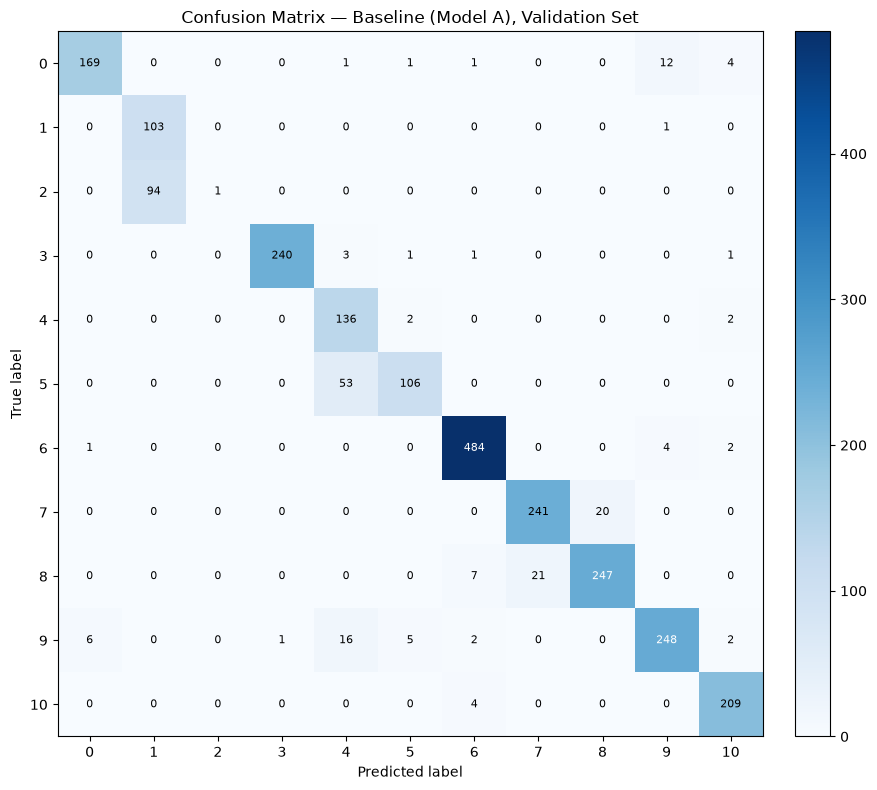

In [14]:
cm = confusion_matrix(y_val, val_preds, labels=sorted(np.unique(y_train)))

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(n_classes))
ax.set_yticks(range(n_classes))
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Confusion Matrix — Baseline (Model A), Validation Set")
for i in range(n_classes):
    for j in range(n_classes):
        val = cm[i, j]
        color = "white" if val > cm.max() / 2 else "black"
        ax.text(j, i, str(val), ha="center", va="center", color=color, fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig("results/figures/baseline_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()


## Experiment Tracking

From this point on, every experiment's key configuration and validation
metrics are appended as one row to `results/metrics/experiment_log.csv` via
the helper below, so Phase 7's comparison table (later in this notebook) is
built from a single authoritative, real, machine-written log rather than
numbers retyped by hand.


In [15]:
classes_sorted = sorted(np.unique(y_train))

import csv

EXPERIMENT_LOG_PATH = METRICS_DIR / "experiment_log.csv"
EXPERIMENT_LOG_FIELDS = [
    "experiment", "architecture", "main_change", "total_params",
    "learning_rate", "batch_size", "early_stopping_patience", "epochs_run", "best_epoch",
    "accuracy", "macro_precision", "macro_recall", "macro_f1",
    "class1_f1", "class2_f1", "class4_f1", "class5_f1", "notes",
]

def log_experiment(row: dict):
    """Append one experiment's config + validation metrics to the experiment log CSV."""
    row = {k: row.get(k, "") for k in EXPERIMENT_LOG_FIELDS}
    file_exists = EXPERIMENT_LOG_PATH.exists()
    with open(EXPERIMENT_LOG_PATH, "a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=EXPERIMENT_LOG_FIELDS)
        if not file_exists:
            writer.writeheader()
        writer.writerow(row)
    print(f"Logged experiment: {row['experiment']}")

# Start the log fresh each time this notebook is run top-to-bottom, so repeated
# runs do not silently accumulate duplicate rows.
if EXPERIMENT_LOG_PATH.exists():
    EXPERIMENT_LOG_PATH.unlink()


In [16]:
idx1_g = classes_sorted.index(1)
idx2_g = classes_sorted.index(2)
idx4_g = classes_sorted.index(4)
idx5_g = classes_sorted.index(5)

log_experiment({
    "experiment": "Exp1: Baseline Model A",
    "architecture": "Model A (3 conv blocks, 16-32-64 filters, Flatten+Dense64)",
    "main_change": "baseline (no augmentation, no class weighting)",
    "total_params": model_a.count_params(),
    "learning_rate": 1e-3,
    "batch_size": 64,
    "early_stopping_patience": 5,
    "epochs_run": len(history.history["loss"]),
    "best_epoch": int(np.argmin(history.history["val_loss"])) + 1,
    "accuracy": round(val_accuracy, 4),
    "macro_precision": round(macro_precision, 4),
    "macro_recall": round(macro_recall, 4),
    "macro_f1": round(macro_f1, 4),
    "class1_f1": round(per_class_f1[idx1_g], 4),
    "class2_f1": round(per_class_f1[idx2_g], 4),
    "class4_f1": round(per_class_f1[idx4_g], 4),
    "class5_f1": round(per_class_f1[idx5_g], 4),
    "notes": "reference baseline; run-to-run Macro F1 varies by ~0.01-0.02 on CPU (see reproducibility audit)",
})


Logged experiment: Exp1: Baseline Model A


---
# Error Analysis (Phase 2)

Detailed analysis of where the baseline (Model A) actually goes wrong on the
**validation set**, using the model and predictions already computed in
Section 10 above. The test set is not touched anywhere in this section.


In [17]:
confidence = val_probs.max(axis=1)  # model's own confidence (max softmax prob) per validation sample

# All misclassification pairs, sorted by frequency (excluding the diagonal)
pairs = []
for i, true_c in enumerate(classes_sorted):
    for j, pred_c in enumerate(classes_sorted):
        if i != j and cm[i, j] > 0:
            pairs.append((cm[i, j], true_c, pred_c))
pairs.sort(reverse=True)

print("Top confusion pairs (true -> predicted), all classes:")
print(f"{'Count':>6} | {'True':>5} | {'Predicted':>9}")
for count, true_c, pred_c in pairs[:10]:
    flag = "  <-- class 1/2 pair" if {true_c, pred_c} == {1, 2} else ""
    print(f"{count:>6} | {true_c:>5} | {pred_c:>9}{flag}")


Top confusion pairs (true -> predicted), all classes:
 Count |  True | Predicted
    94 |     2 |         1  <-- class 1/2 pair
    53 |     5 |         4
    21 |     8 |         7
    20 |     7 |         8
    16 |     9 |         4
    12 |     0 |         9
     7 |     8 |         6
     6 |     9 |         0
     5 |     9 |         5
     4 |    10 |         6


In [18]:
mask_correct1 = (y_val == 1) & (val_preds == 1)
mask_correct2 = (y_val == 2) & (val_preds == 2)
mask_1as2 = (y_val == 1) & (val_preds == 2)
mask_2as1 = (y_val == 2) & (val_preds == 1)

print(f"Correct class 1 predictions: {mask_correct1.sum()} / {(y_val==1).sum()}")
print(f"Correct class 2 predictions: {mask_correct2.sum()} / {(y_val==2).sum()}")
print(f"Class 1 misclassified as class 2: {mask_1as2.sum()}")
print(f"Class 2 misclassified as class 1: {mask_2as1.sum()}")


Correct class 1 predictions: 103 / 104
Correct class 2 predictions: 1 / 95
Class 1 misclassified as class 2: 0
Class 2 misclassified as class 1: 94


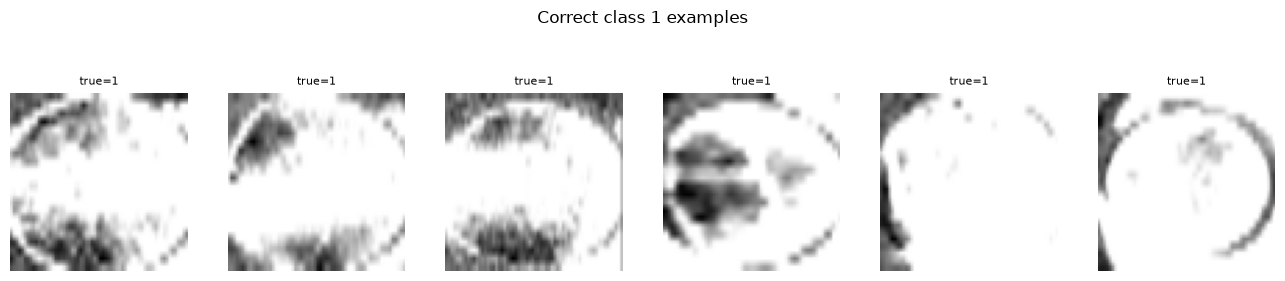

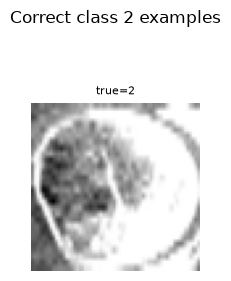

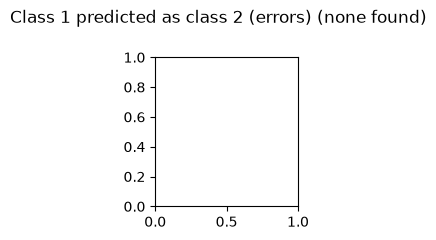

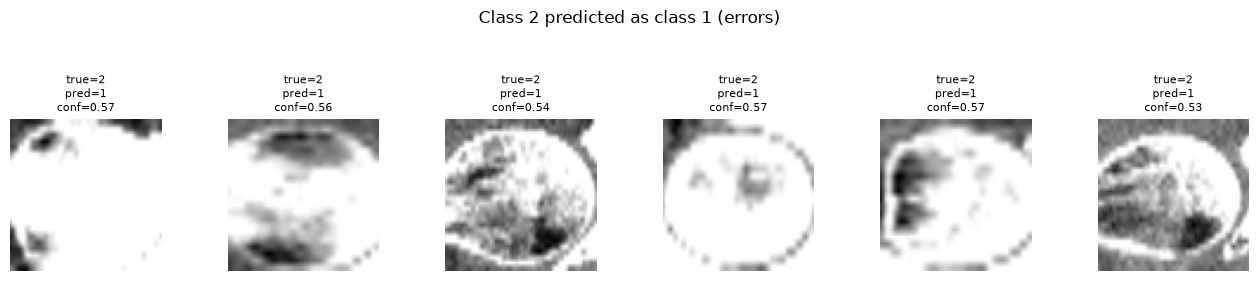

In [19]:
def show_grid(mask, title, n=6, show_pred=False):
    idxs = np.where(mask)[0][:n]
    fig, axes = plt.subplots(1, max(len(idxs), 1), figsize=(2.2 * max(len(idxs), 1), 2.4))
    if len(idxs) <= 1:
        axes = [axes]
    for ax, idx in zip(axes, idxs):
        ax.imshow(X_val[idx, :, :, 0], cmap="gray")
        label = f"true={y_val[idx]}"
        if show_pred:
            label += f"\npred={val_preds[idx]}\nconf={confidence[idx]:.2f}"
        ax.set_title(label, fontsize=8)
        ax.axis("off")
    if len(idxs) == 0:
        fig.suptitle(f"{title} (none found)")
    else:
        fig.suptitle(title, y=1.15)
    plt.tight_layout()
    return fig

fig1 = show_grid(mask_correct1, "Correct class 1 examples")
plt.savefig(FIGURES_DIR / "error_analysis_correct_class1.png", dpi=120, bbox_inches="tight")
plt.show()

fig2 = show_grid(mask_correct2, "Correct class 2 examples")
plt.savefig(FIGURES_DIR / "error_analysis_correct_class2.png", dpi=120, bbox_inches="tight")
plt.show()

fig3 = show_grid(mask_1as2, "Class 1 predicted as class 2 (errors)", show_pred=True)
plt.savefig(FIGURES_DIR / "error_analysis_1_as_2.png", dpi=120, bbox_inches="tight")
plt.show()

fig4 = show_grid(mask_2as1, "Class 2 predicted as class 1 (errors)", show_pred=True)
plt.savefig(FIGURES_DIR / "error_analysis_2_as_1.png", dpi=120, bbox_inches="tight")
plt.show()


### Is the Model Uncertain or Confidently Wrong?

Comparing the model's own confidence (max softmax probability) on correct vs.
incorrect predictions, and specifically on the class 1/2 confusion errors.


Mean confidence, correct predictions (all classes):   0.937
Mean confidence, incorrect predictions (all classes): 0.663

Mean confidence, class 1 -> predicted class 2 errors: nan
Mean confidence, class 2 -> predicted class 1 errors: 0.568


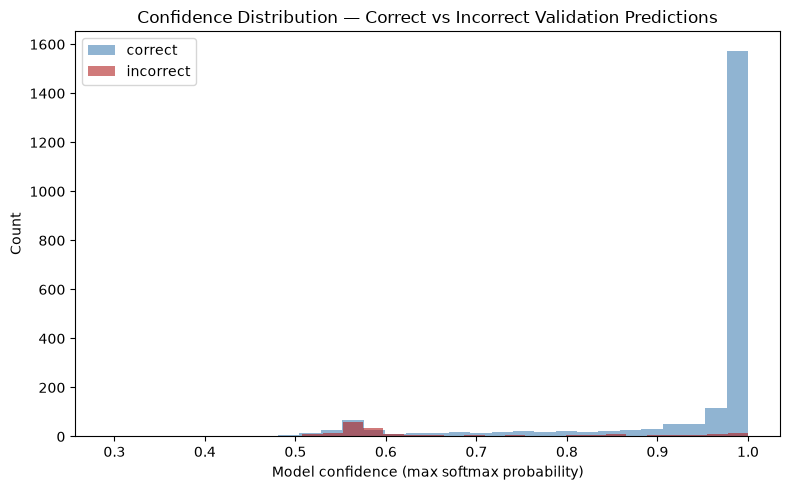

In [20]:
correct_mask_all = (val_preds == y_val)
incorrect_mask_all = ~correct_mask_all

print(f"Mean confidence, correct predictions (all classes):   {confidence[correct_mask_all].mean():.3f}")
print(f"Mean confidence, incorrect predictions (all classes): {confidence[incorrect_mask_all].mean():.3f}")
print()
print(f"Mean confidence, class 1 -> predicted class 2 errors: {confidence[mask_1as2].mean() if mask_1as2.sum() else float('nan'):.3f}")
print(f"Mean confidence, class 2 -> predicted class 1 errors: {confidence[mask_2as1].mean() if mask_2as1.sum() else float('nan'):.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(confidence[correct_mask_all], bins=30, alpha=0.6, label="correct", color="steelblue")
ax.hist(confidence[incorrect_mask_all], bins=30, alpha=0.6, label="incorrect", color="firebrick")
ax.set_xlabel("Model confidence (max softmax probability)")
ax.set_ylabel("Count")
ax.set_title("Confidence Distribution — Correct vs Incorrect Validation Predictions")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "error_analysis_confidence_distribution.png", dpi=120, bbox_inches="tight")
plt.show()


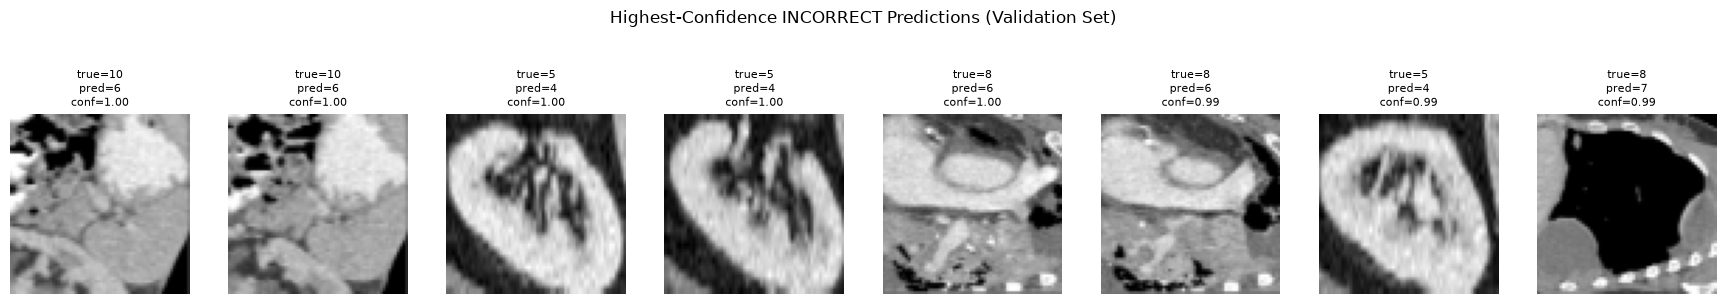

These are the errors the model is most confident about — if these are visually
ambiguous even to a human, that points toward genuine visual similarity between
the confused classes rather than a fixable modeling weakness.


In [21]:
top_n = 8
incorrect_idxs = np.where(incorrect_mask_all)[0]
order = incorrect_idxs[np.argsort(-confidence[incorrect_idxs])][:top_n]

fig, axes = plt.subplots(1, top_n, figsize=(2.2 * top_n, 2.6))
for ax, idx in zip(axes, order):
    ax.imshow(X_val[idx, :, :, 0], cmap="gray")
    ax.set_title(f"true={y_val[idx]}\npred={val_preds[idx]}\nconf={confidence[idx]:.2f}", fontsize=8)
    ax.axis("off")
fig.suptitle("Highest-Confidence INCORRECT Predictions (Validation Set)", y=1.15)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "error_analysis_top_confident_errors.png", dpi=120, bbox_inches="tight")
plt.show()

print("These are the errors the model is most confident about — if these are visually")
print("ambiguous even to a human, that points toward genuine visual similarity between")
print("the confused classes rather than a fixable modeling weakness.")


---
# Data-Quality Checks (Phase 3)

Checking whether classes 1 and 2 show any obvious data-quality differences
(blank/near-blank images, abnormal intensity, unusual variance) that might
explain the confusion — **without** modifying, relabeling, or deleting
anything in the dataset. Any suspicious samples found are flagged for manual
review only.


In [22]:
def class_pixel_stats(images, labels, class_id):
    imgs = images[labels == class_id].astype(np.float64)
    per_image_mean = imgs.mean(axis=(1, 2))
    per_image_var = imgs.var(axis=(1, 2))
    near_zero_frac = (imgs < 10).mean(axis=(1, 2))  # fraction of near-black pixels per image
    return {
        "n": len(imgs),
        "mean_intensity": per_image_mean.mean(),
        "std_intensity": per_image_mean.std(),
        "mean_variance": per_image_var.mean(),
        "mean_near_zero_frac": near_zero_frac.mean(),
        "per_image_mean": per_image_mean,
        "per_image_var": per_image_var,
        "near_zero_frac": near_zero_frac,
    }

stats_by_class = {c: class_pixel_stats(train_images, train_labels, c) for c in classes_sorted}

print(f"{'Class':>6} | {'N':>5} | {'MeanIntensity':>13} | {'StdIntensity':>12} | {'MeanVariance':>12} | {'MeanNearZero%':>13}")
for c in classes_sorted:
    s = stats_by_class[c]
    flag = "  <-- watch" if c in (1, 2, 4, 5) else ""
    print(f"{c:>6} | {s['n']:>5} | {s['mean_intensity']:>13.2f} | {s['std_intensity']:>12.2f} | "
          f"{s['mean_variance']:>12.1f} | {100*s['mean_near_zero_frac']:>12.2f}%{flag}")


 Class |     N | MeanIntensity | StdIntensity | MeanVariance | MeanNearZero%
     0 |  1148 |        115.13 |        18.42 |       1659.9 |         2.88%
     1 |   630 |        185.14 |        57.27 |       1926.2 |         2.57%  <-- watch
     2 |   614 |        183.05 |        58.28 |       1893.4 |         3.44%  <-- watch
     3 |   721 |        136.98 |        38.61 |       4791.9 |        16.71%
     4 |  1132 |        124.58 |        27.04 |       2878.7 |         3.49%  <-- watch
     5 |  1119 |        134.31 |        29.54 |       2941.8 |         2.26%  <-- watch
     6 |  3464 |        128.02 |        20.47 |       3861.0 |         9.78%
     7 |   741 |         69.53 |        17.92 |       5508.1 |        44.32%
     8 |   803 |         68.19 |        18.52 |       5561.7 |        47.30%
     9 |  2004 |        135.59 |        27.99 |       2403.9 |         0.89%
    10 |  1556 |        119.96 |        25.63 |       3181.7 |         7.60%


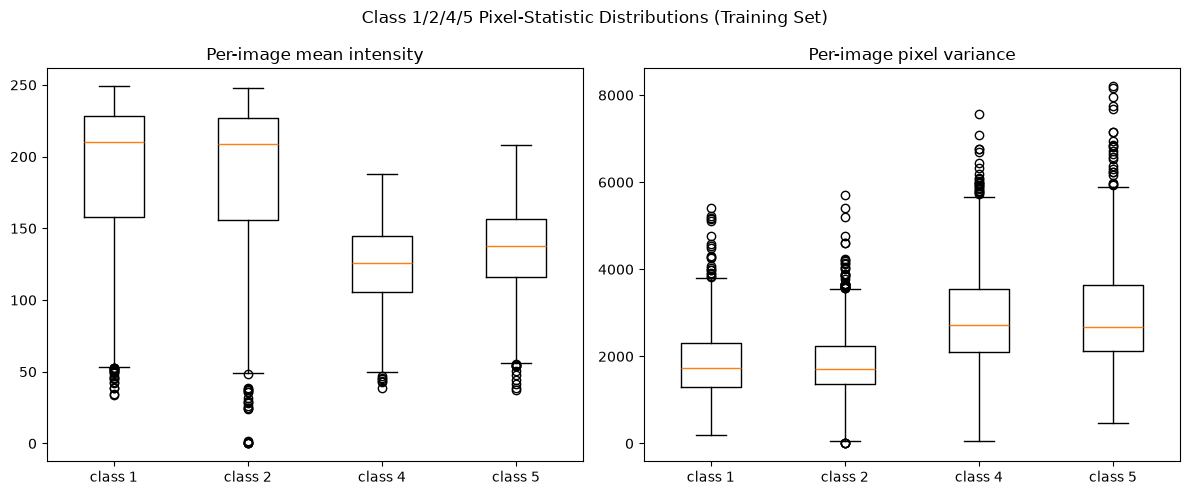

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, metric, title in [
    (axes[0], "per_image_mean", "Per-image mean intensity"),
    (axes[1], "per_image_var", "Per-image pixel variance"),
]:
    data = [stats_by_class[c][metric] for c in (1, 2, 4, 5)]
    ax.boxplot(data, tick_labels=["class 1", "class 2", "class 4", "class 5"])
    ax.set_title(title)
plt.suptitle("Class 1/2/4/5 Pixel-Statistic Distributions (Training Set)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "data_quality_class_boxplots.png", dpi=120, bbox_inches="tight")
plt.show()


In [24]:
# Flag outliers: images whose per-image variance is unusually low (near-blank/near-constant)
# within their own class, using each class's 1st percentile as the threshold. Flagged for
# manual review only -- nothing is removed, relabeled, or modified.
print("Potential near-blank / low-variance outliers flagged for manual review (not removed):")
any_flagged = False
for c in (1, 2, 4, 5):
    var = stats_by_class[c]["per_image_var"]
    threshold = np.percentile(var, 1)
    n_flagged = int((var <= threshold).sum())
    if n_flagged:
        any_flagged = True
    print(f"  class {c}: {n_flagged} images at/below the 1st percentile of within-class variance ({threshold:.1f})")
if not any_flagged:
    print("  (none met even this loose threshold in any watched class)")


Potential near-blank / low-variance outliers flagged for manual review (not removed):
  class 1: 7 images at/below the 1st percentile of within-class variance (538.8)
  class 2: 7 images at/below the 1st percentile of within-class variance (236.4)
  class 4: 12 images at/below the 1st percentile of within-class variance (678.3)
  class 5: 12 images at/below the 1st percentile of within-class variance (966.0)


**Observation, not a conclusion:** any differences printed above between
classes 1, 2, 4, and 5 (or the absence of differences) are reported as
measured facts. Whether they explain the confusion is assessed after seeing
the actual numbers — not assumed in advance. No image is claimed to be
mislabeled based on misclassification alone; that would require independent
verification against ground truth this project does not have access to.


---
# Experiment 2 — Class-Weighted Loss

**Goal:** isolate the effect of class weighting on the baseline architecture.
Everything about Model A stays identical (same layers, filters, dropout,
optimizer, learning rate, batch size, preprocessing, split, no augmentation).
The **only** intentional change is passing `class_weight` to `model.fit(...)`.

Baseline numbers this experiment will be compared against (computed earlier in
this same notebook run, Section 10): Accuracy, Macro F1, per-class F1, and the
confusion matrix already stored in `val_accuracy`, `macro_f1`, `per_class_f1`,
and `cm`.


## Step 1 — Calculate Class Weights (Training Labels Only)

Using scikit-learn's standard **"balanced"** class weighting scheme:

$$w_c = \frac{n_{\text{samples}}}{n_{\text{classes}} \times n_{\text{samples},c}}$$

This gives each class a weight inversely proportional to its frequency — rare
classes get a higher weight, so their per-sample loss contributes more to the
total loss, pushing the optimizer to pay more attention to them. Computed
**only from `y_train`** — validation and test labels are not used here, exactly
as in every other part of this project.


In [25]:
from sklearn.utils.class_weight import compute_class_weight

classes_sorted = sorted(np.unique(y_train))
weights_array = compute_class_weight(class_weight="balanced", classes=np.array(classes_sorted), y=y_train)
class_weight_dict = {c: w for c, w in zip(classes_sorted, weights_array)}

print(f"{'Class':>6} | {'Training Samples':>17} | {'Class Weight':>13}")
for c in classes_sorted:
    n_samples_c = int((y_train == c).sum())
    print(f"{c:>6} | {n_samples_c:>17} | {class_weight_dict[c]:>13.4f}")

# Sanity check: minority classes should receive the highest weights
min_class = min(class_weight_dict, key=lambda c: (y_train == c).sum())
max_class = max(class_weight_dict, key=lambda c: (y_train == c).sum())
print(f"\nSmallest class ({min_class}) weight: {class_weight_dict[min_class]:.4f}")
print(f"Largest class ({max_class}) weight: {class_weight_dict[max_class]:.4f}")
assert class_weight_dict[min_class] > class_weight_dict[max_class], "Expected the smallest class to receive the largest weight"
print("Confirmed: minority classes receive higher weights, as expected for balanced weighting.")


 Class |  Training Samples |  Class Weight
     0 |              1148 |        1.1033
     1 |               630 |        2.0104
     2 |               614 |        2.0628
     3 |               721 |        1.7567
     4 |              1132 |        1.1189
     5 |              1119 |        1.1319
     6 |              3464 |        0.3656
     7 |               741 |        1.7092
     8 |               803 |        1.5773
     9 |              2004 |        0.6320
    10 |              1556 |        0.8140

Smallest class (2) weight: 2.0628
Largest class (6) weight: 0.3656
Confirmed: minority classes receive higher weights, as expected for balanced weighting.


## Step 2 — Train Model A (Identical Architecture) With Class Weights

We rebuild a **fresh instance** of the exact same `build_model_a(...)` function
used for the baseline, and reset the random seed immediately beforehand so its
initial weights match the baseline's initial weights. This way, the *only*
difference between this run and the baseline run is the `class_weight`
argument passed to `.fit(...)` — everything else (architecture, optimizer,
learning rate, batch size, callbacks, epochs budget) is identical, which is
what makes this a controlled experiment.


In [26]:
# Re-seed so this model's initialization matches the baseline's initialization exactly
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

model_a_weighted = build_model_a(input_shape=X_train.shape[1:], n_classes=n_classes)
model_a_weighted.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks_weighted = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        "models/model_a_weighted_best.keras", monitor="val_loss", save_best_only=True, verbose=1
    ),
]

history_weighted = model_a_weighted.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=callbacks_weighted,
    verbose=2,
)


Epoch 1/30


E0000 00:00:1787859873.013518  205690 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


E0000 00:00:1787859886.074150  205690 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}



Epoch 1: val_loss improved from None to 0.91168, saving model to models/model_a_weighted_best.keras



Epoch 1: finished saving model to models/model_a_weighted_best.keras


218/218 - 14s - 65ms/step - accuracy: 0.3320 - loss: 1.7772 - val_accuracy: 0.7280 - val_loss: 0.9117


... (44 outputs left out)


Epoch 14: val_loss did not improve from 0.31391


218/218 - 12s - 56ms/step - accuracy: 0.8068 - loss: 0.4787 - val_accuracy: 0.8781 - val_loss: 0.3336


Epoch 14: early stopping


Restoring model weights from the end of the best epoch: 9.


## Step 3 — Validation Evaluation (Class-Weighted Model)

Exactly the same metric suite as the baseline (Section 10), computed on the
**same validation set**, so the two are directly comparable. Test set still untouched.


In [27]:
val_probs_w = model_a_weighted.predict(X_val, verbose=0)
val_preds_w = np.argmax(val_probs_w, axis=1)

val_accuracy_w = accuracy_score(y_val, val_preds_w)
macro_precision_w, macro_recall_w, macro_f1_w, _ = precision_recall_fscore_support(
    y_val, val_preds_w, average="macro", zero_division=0
)

print(f"Validation Accuracy:        {val_accuracy_w:.4f}")
print(f"Validation Macro Precision: {macro_precision_w:.4f}")
print(f"Validation Macro Recall:    {macro_recall_w:.4f}")
print(f"Validation Macro F1:        {macro_f1_w:.4f}   <-- primary metric")


E0000 00:00:1787860046.926587  205690 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Validation Accuracy:        0.8732
Validation Macro Precision: 0.7808
Validation Macro Recall:    0.8148
Validation Macro F1:        0.7833   <-- primary metric


In [28]:
per_class_precision_w, per_class_recall_w, per_class_f1_w, per_class_support_w = precision_recall_fscore_support(
    y_val, val_preds_w, average=None, zero_division=0, labels=classes_sorted
)

print(f"{'Class':>6} | {'Precision':>10} | {'Recall':>8} | {'F1':>8} | {'Support':>8}")
for c, p, r, f, s in zip(classes_sorted, per_class_precision_w, per_class_recall_w, per_class_f1_w, per_class_support_w):
    print(f"{c:>6} | {p:>10.3f} | {r:>8.3f} | {f:>8.3f} | {s:>8d}")


 Class |  Precision |   Recall |       F1 |  Support
     0 |      0.941 |    0.926 |    0.933 |      188
     1 |      0.515 |    0.981 |    0.675 |      104
     2 |      0.000 |    0.000 |    0.000 |       95
     3 |      0.980 |    0.996 |    0.988 |      246
     4 |      0.612 |    0.936 |    0.740 |      140
     5 |      0.937 |    0.560 |    0.701 |      159
     6 |      0.974 |    0.982 |    0.978 |      491
     7 |      0.924 |    0.835 |    0.877 |      261
     8 |      0.854 |    0.913 |    0.882 |      275
     9 |      0.942 |    0.868 |    0.903 |      280
    10 |      0.912 |    0.967 |    0.938 |      213


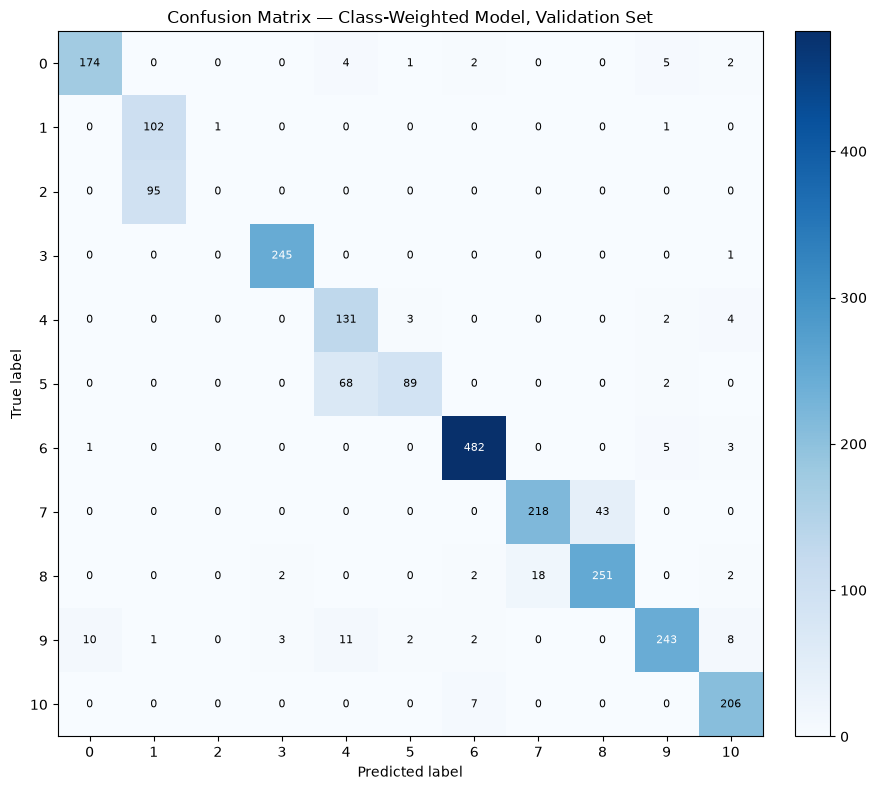

In [29]:
cm_w = confusion_matrix(y_val, val_preds_w, labels=classes_sorted)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_w, cmap="Blues")
ax.set_xticks(range(n_classes))
ax.set_yticks(range(n_classes))
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Confusion Matrix — Class-Weighted Model, Validation Set")
for i in range(n_classes):
    for j in range(n_classes):
        val = cm_w[i, j]
        color = "white" if val > cm_w.max() / 2 else "black"
        ax.text(j, i, str(val), ha="center", va="center", color=color, fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig("results/figures/exp2_weighted_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()


## Step 4 — Direct Comparison: Baseline vs Class-Weighted


In [30]:
print(f"{'Metric':>18} | {'Baseline':>10} | {'Class Weighted':>15} | {'Change':>9}")
for name, base_val, w_val in [
    ("Accuracy", val_accuracy, val_accuracy_w),
    ("Macro Precision", macro_precision, macro_precision_w),
    ("Macro Recall", macro_recall, macro_recall_w),
    ("Macro F1", macro_f1, macro_f1_w),
]:
    change = w_val - base_val
    print(f"{name:>18} | {base_val:>10.4f} | {w_val:>15.4f} | {change:>+9.4f}")


            Metric |   Baseline |  Class Weighted |    Change
          Accuracy |     0.8907 |          0.8732 |   -0.0175
   Macro Precision |     0.8866 |          0.7808 |   -0.1057
      Macro Recall |     0.8353 |          0.8148 |   -0.0205
          Macro F1 |     0.8053 |          0.7833 |   -0.0220


In [31]:
print(f"{'Class':>6} | {'Baseline F1':>11} | {'Weighted F1':>11} | {'Change':>8}")
for c, f_base, f_w in zip(classes_sorted, per_class_f1, per_class_f1_w):
    change = f_w - f_base
    flag = "  <-- watch" if c in (1, 2) else ""
    print(f"{c:>6} | {f_base:>11.3f} | {f_w:>11.3f} | {change:>+8.3f}{flag}")


 Class | Baseline F1 | Weighted F1 |   Change
     0 |       0.929 |       0.933 |   +0.004
     1 |       0.684 |       0.675 |   -0.009  <-- watch
     2 |       0.021 |       0.000 |   -0.021  <-- watch
     3 |       0.986 |       0.988 |   +0.002
     4 |       0.779 |       0.740 |   -0.039
     5 |       0.774 |       0.701 |   -0.073
     6 |       0.978 |       0.978 |   -0.000
     7 |       0.922 |       0.877 |   -0.044
     8 |       0.911 |       0.882 |   -0.029
     9 |       0.910 |       0.903 |   -0.007
    10 |       0.965 |       0.938 |   -0.027


## Step 5 — Confusion Matrix Analysis: Did Class Weighting Fix the Class 1/2 Confusion?

Answering each question directly from the computed numbers above (not
speculation) — index positions in `cm` / `cm_w` correspond to `classes_sorted`,
so `cm[2, 1]` is "true class 2, predicted as class 1".


In [32]:
idx1 = classes_sorted.index(1)
idx2 = classes_sorted.index(2)

class2_recall_base, class2_recall_w = per_class_recall[idx2], per_class_recall_w[idx2]
class2_f1_base, class2_f1_w = per_class_f1[idx2], per_class_f1_w[idx2]
class1_precision_base, class1_precision_w = per_class_precision[idx1], per_class_precision_w[idx1]
class1_recall_base, class1_recall_w = per_class_recall[idx1], per_class_recall_w[idx1]

class2_as_1_base = cm[idx2, idx1]
class2_as_1_w = cm_w[idx2, idx1]
class2_total_base = cm[idx2].sum()
class2_total_w = cm_w[idx2].sum()

print("Q: Did class 2 recall improve?")
print(f"   Baseline: {class2_recall_base:.3f} -> Weighted: {class2_recall_w:.3f}  (change {class2_recall_w - class2_recall_base:+.3f})")
print()
print("Q: Did class 2 F1 improve?")
print(f"   Baseline: {class2_f1_base:.3f} -> Weighted: {class2_f1_w:.3f}  (change {class2_f1_w - class2_f1_base:+.3f})")
print()
print("Q: Did class 1 precision/recall change?")
print(f"   Precision: {class1_precision_base:.3f} -> {class1_precision_w:.3f}  (change {class1_precision_w - class1_precision_base:+.3f})")
print(f"   Recall:    {class1_recall_base:.3f} -> {class1_recall_w:.3f}  (change {class1_recall_w - class1_recall_base:+.3f})")
print()
print("Q: How many true-class-2 validation samples were predicted as class 1?")
print(f"   Baseline: {class2_as_1_base} / {class2_total_base} true class-2 samples")
print(f"   Weighted: {class2_as_1_w} / {class2_total_w} true class-2 samples")
print()
print("Q: Did overall Macro F1 improve?")
print(f"   Baseline: {macro_f1:.4f} -> Weighted: {macro_f1_w:.4f}  (change {macro_f1_w - macro_f1:+.4f})")


Q: Did class 2 recall improve?
   Baseline: 0.011 -> Weighted: 0.000  (change -0.011)

Q: Did class 2 F1 improve?
   Baseline: 0.021 -> Weighted: 0.000  (change -0.021)

Q: Did class 1 precision/recall change?
   Precision: 0.523 -> 0.515  (change -0.008)
   Recall:    0.990 -> 0.981  (change -0.010)

Q: How many true-class-2 validation samples were predicted as class 1?
   Baseline: 94 / 95 true class-2 samples
   Weighted: 95 / 95 true class-2 samples

Q: Did overall Macro F1 improve?
   Baseline: 0.8053 -> Weighted: 0.7833  (change -0.0220)


In [33]:
majority_classes = [c for c in classes_sorted if c not in (1, 2)]
print("Q: Did performance on the majority (non-1/2) classes degrade?")
print(f"{'Class':>6} | {'Baseline F1':>11} | {'Weighted F1':>11} | {'Change':>8}")
degraded = []
for c in majority_classes:
    idx = classes_sorted.index(c)
    f_base, f_w = per_class_f1[idx], per_class_f1_w[idx]
    change = f_w - f_base
    print(f"{c:>6} | {f_base:>11.3f} | {f_w:>11.3f} | {change:>+8.3f}")
    if change < -0.02:
        degraded.append(c)
print()
if degraded:
    print(f"Classes with a >0.02 F1 drop: {degraded}")
else:
    print("No majority class dropped by more than 0.02 F1.")


Q: Did performance on the majority (non-1/2) classes degrade?
 Class | Baseline F1 | Weighted F1 |   Change
     0 |       0.929 |       0.933 |   +0.004
     3 |       0.986 |       0.988 |   +0.002
     4 |       0.779 |       0.740 |   -0.039
     5 |       0.774 |       0.701 |   -0.073
     6 |       0.978 |       0.978 |   -0.000
     7 |       0.922 |       0.877 |   -0.044
     8 |       0.911 |       0.882 |   -0.029
     9 |       0.910 |       0.903 |   -0.007
    10 |       0.965 |       0.938 |   -0.027

Classes with a >0.02 F1 drop: [np.int32(4), np.int32(5), np.int32(7), np.int32(8), np.int32(10)]


In [34]:
f1_std_base = np.std(per_class_f1)
f1_std_w = np.std(per_class_f1_w)
f1_min_base, f1_min_w = per_class_f1.min(), per_class_f1_w.min()
f1_range_base = per_class_f1.max() - per_class_f1.min()
f1_range_w = per_class_f1_w.max() - per_class_f1_w.min()

print("Q: Did the model become more balanced across classes?")
print(f"   Per-class F1 std dev:   baseline={f1_std_base:.4f}  weighted={f1_std_w:.4f}")
print(f"   Per-class F1 min:       baseline={f1_min_base:.4f}  weighted={f1_min_w:.4f}")
print(f"   Per-class F1 range:     baseline={f1_range_base:.4f}  weighted={f1_range_w:.4f}")
print("   (Lower std/range across classes = more balanced performance across classes.)")


Q: Did the model become more balanced across classes?
   Per-class F1 std dev:   baseline=0.2647  weighted=0.2685
   Per-class F1 min:       baseline=0.0208  weighted=0.0000
   Per-class F1 range:     baseline=0.9648  weighted=0.9879
   (Lower std/range across classes = more balanced performance across classes.)


## Step 6 — Training Behavior: Convergence and Overfitting

Same plot format as the baseline (Section 9), for direct visual comparison.


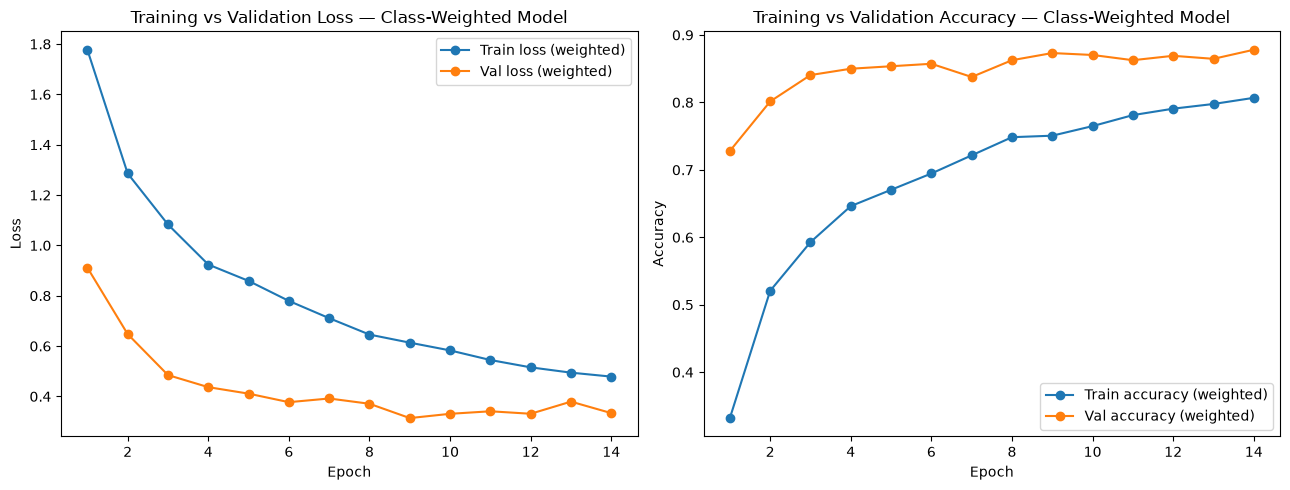

Baseline trained for 17 epochs; class-weighted model trained for 14 epochs.
Baseline best val_loss: 0.2867 at epoch 12
Weighted best val_loss: 0.3139 at epoch 9
Baseline final train/val loss gap: -0.0073
Weighted final train/val loss gap: -0.1450


In [35]:
history_df_w = history_weighted.history
epochs_range_w = range(1, len(history_df_w["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(epochs_range_w, history_df_w["loss"], label="Train loss (weighted)", marker="o")
axes[0].plot(epochs_range_w, history_df_w["val_loss"], label="Val loss (weighted)", marker="o")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training vs Validation Loss — Class-Weighted Model")
axes[0].legend()

axes[1].plot(epochs_range_w, history_df_w["accuracy"], label="Train accuracy (weighted)", marker="o")
axes[1].plot(epochs_range_w, history_df_w["val_accuracy"], label="Val accuracy (weighted)", marker="o")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training vs Validation Accuracy — Class-Weighted Model")
axes[1].legend()

plt.tight_layout()
plt.savefig("results/figures/exp2_weighted_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"Baseline trained for {len(epochs_range)} epochs; class-weighted model trained for {len(epochs_range_w)} epochs.")
print(f"Baseline best val_loss: {min(history_df['val_loss']):.4f} at epoch {np.argmin(history_df['val_loss']) + 1}")
print(f"Weighted best val_loss: {min(history_df_w['val_loss']):.4f} at epoch {np.argmin(history_df_w['val_loss']) + 1}")
print(f"Baseline final train/val loss gap: {history_df['val_loss'][-1] - history_df['loss'][-1]:+.4f}")
print(f"Weighted final train/val loss gap: {history_df_w['val_loss'][-1] - history_df_w['loss'][-1]:+.4f}")


In [36]:
log_experiment({
    "experiment": "Exp2: Model A + Class Weighting",
    "architecture": "Model A (identical to Exp1)",
    "main_change": "class_weight='balanced' passed to model.fit(); no augmentation",
    "total_params": model_a_weighted.count_params(),
    "learning_rate": 1e-3,
    "batch_size": 64,
    "early_stopping_patience": 5,
    "epochs_run": len(history_weighted.history["loss"]),
    "best_epoch": int(np.argmin(history_weighted.history["val_loss"])) + 1,
    "accuracy": round(val_accuracy_w, 4),
    "macro_precision": round(macro_precision_w, 4),
    "macro_recall": round(macro_recall_w, 4),
    "macro_f1": round(macro_f1_w, 4),
    "class1_f1": round(per_class_f1_w[idx1_g], 4),
    "class2_f1": round(per_class_f1_w[idx2_g], 4),
    "class4_f1": round(per_class_f1_w[idx4_g], 4),
    "class5_f1": round(per_class_f1_w[idx5_g], 4),
    "notes": "NEGATIVE RESULT: reduced Macro F1 vs Exp1; class 2 recall/F1 got worse, not better",
})


Logged experiment: Exp2: Model A + Class Weighting


---
# Experiment 3 — Data Augmentation

**Goal:** isolate the effect of training-time data augmentation on the baseline
architecture. Per the Experiment 2 result (class weighting reduced Macro F1 and
made the class 1/2 confusion worse), **class-weighted loss is NOT used in this
experiment** — augmentation is tested against the plain baseline configuration,
not on top of class weighting.

**Controlled variable:** everything about Model A is identical to the baseline
(architecture, filters, dropout, optimizer, learning rate, batch size, loss
function, no class weights, same split). The **only** intentional change is
that training images are randomly, mildly transformed on-the-fly during
training. Validation images are evaluated exactly as-is, with no augmentation
applied.


## Augmentation Design

Conservative, label-preserving transformations only, since these are medical
CT images where excessive distortion could produce anatomically implausible
inputs:

- **Rotation:** ±10°
- **Translation:** ±5% of image size (~±3 px on a 64×64 image)
- **Zoom:** ±10%
- **Fill mode:** constant fill with value 0 (black) for any pixels exposed by
  rotation/translation/zoom — chosen because the pixel-intensity analysis
  earlier in this notebook showed the image background is black (near 0), so
  constant-black fill is the most anatomically consistent choice; reflecting
  or wrapping the image could fabricate tissue-like patterns at the border.

### Why NOT horizontal flip

Horizontal flipping is deliberately excluded at this stage. If any of the 11
classes represent bilateral anatomical structures that come in mirrored
left/right pairs, flipping an image of the "left" structure would make it look
exactly like the "right" structure **without changing its label** — this would
inject incorrect training signal, actively teaching the model that left/right
mirrored images are interchangeable when they are not.

We don't need the (unverified) organ-name hypothesis to justify this: the
**empirical evidence from Experiments 1 and 2** already shows classes 1 and 2
are heavily confused with each other in a highly asymmetric, mirror-like
pattern (in the baseline, 81 of 95 true class-2 validation samples were
predicted as class 1). If 1 and 2 are in fact mirrored structures, horizontal
flipping would actively worsen exactly this confusion by making genuine
class-1 and class-2 images look alike during training. Until that's ruled out,
flipping is avoided as a precaution.


In [37]:
augmentation = keras.Sequential([
    layers.RandomRotation(factor=10/360, fill_mode="constant", fill_value=0.0, seed=SEED),
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05, fill_mode="constant", fill_value=0.0, seed=SEED),
    layers.RandomZoom(height_factor=0.1, width_factor=0.1, fill_mode="constant", fill_value=0.0, seed=SEED),
], name="conservative_augmentation")

augmentation.summary()


Model: "conservative_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ ?                      │   0 (unbuilt) │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## Before Training — Original vs Augmented Examples

Visually verifying the augmentation is reasonable and does not destroy
anatomical information, before using it for training. Includes examples from
classes 1 and 2 specifically, since those are the classes under closest
scrutiny.


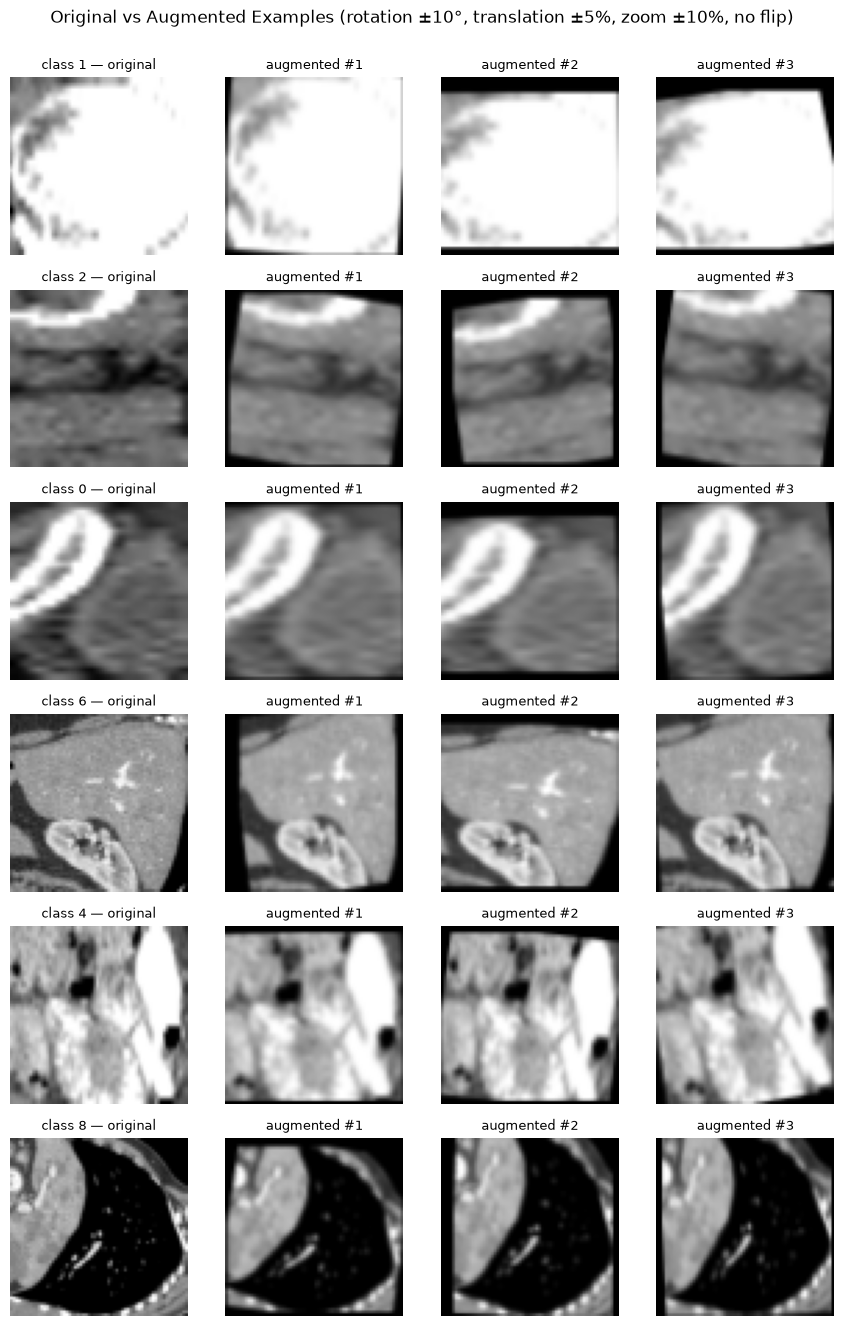

In [38]:
rng_vis = np.random.default_rng(SEED)
example_classes = [1, 2, 0, 6, 4, 8]  # includes the classes of interest plus a few others
n_variants = 3

fig, axes = plt.subplots(len(example_classes), n_variants + 1, figsize=(2.2 * (n_variants + 1), 2.2 * len(example_classes)))

for row, c in enumerate(example_classes):
    idxs = np.where(y_train == c)[0]
    idx = rng_vis.choice(idxs)
    original = X_train[idx:idx+1]  # keep batch dim

    axes[row, 0].imshow(original[0, :, :, 0], cmap="gray")
    axes[row, 0].set_title(f"class {c} — original", fontsize=9)
    axes[row, 0].axis("off")

    for v in range(n_variants):
        augmented = augmentation(original, training=True).numpy()
        axes[row, v + 1].imshow(augmented[0, :, :, 0], cmap="gray")
        axes[row, v + 1].set_title(f"augmented #{v+1}", fontsize=9)
        axes[row, v + 1].axis("off")

plt.suptitle("Original vs Augmented Examples (rotation ±10°, translation ±5%, zoom ±10%, no flip)", y=1.001)
plt.tight_layout()
plt.savefig("results/figures/exp3_augmentation_examples.png", dpi=120, bbox_inches="tight")
plt.show()


## Training — Same Model A, Augmented Training Data Only

Augmentation is applied as a `tf.data` pipeline step on the **training** set
only, so the model architecture itself (`build_model_a`) is untouched — same
pattern as Experiment 2, where only the data fed into `.fit(...)` changed. The
validation dataset is passed through with no augmentation. As in Experiment 2,
we re-seed immediately before building the model so its initial weights match
the baseline's initial weights, isolating augmentation as the only variable.


In [39]:
BATCH_SIZE = 64

train_ds_aug = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(buffer_size=len(X_train), seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .map(lambda x, y: (augmentation(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds_plain = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Re-seed so this model's initialization matches the baseline's initialization exactly
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

model_a_aug = build_model_a(input_shape=X_train.shape[1:], n_classes=n_classes)
model_a_aug.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks_aug = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        "models/model_a_augmented_best.keras", monitor="val_loss", save_best_only=True, verbose=1
    ),
]

history_aug = model_a_aug.fit(
    train_ds_aug,
    validation_data=val_ds_plain,
    epochs=30,
    callbacks=callbacks_aug,
    verbose=2,
)


Epoch 1/30


/home/aryan/Downloads/organsmnist_64/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1787860054.088283  205690 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignor


Epoch 1: val_loss improved from None to 1.00225, saving model to models/model_a_augmented_best.keras



Epoch 1: finished saving model to models/model_a_augmented_best.keras


218/218 - 19s - 85ms/step - accuracy: 0.3783 - loss: 1.7389 - val_accuracy: 0.6399 - val_loss: 1.0023


Epoch 2/30


... (35 outputs left out)


Epoch 12: val_loss did not improve from 0.43864


218/218 - 17s - 80ms/step - accuracy: 0.7382 - loss: 0.6609 - val_accuracy: 0.8352 - val_loss: 0.5269


Epoch 12: early stopping


Restoring model weights from the end of the best epoch: 7.


## Evaluation — Validation Set (No Augmentation Applied)

Same metric suite as the baseline and class-weighted experiments. Test set
still untouched.


In [40]:
val_probs_aug = model_a_aug.predict(X_val, verbose=0)
val_preds_aug = np.argmax(val_probs_aug, axis=1)

val_accuracy_aug = accuracy_score(y_val, val_preds_aug)
macro_precision_aug, macro_recall_aug, macro_f1_aug, _ = precision_recall_fscore_support(
    y_val, val_preds_aug, average="macro", zero_division=0
)

print(f"Validation Accuracy:        {val_accuracy_aug:.4f}")
print(f"Validation Macro Precision: {macro_precision_aug:.4f}")
print(f"Validation Macro Recall:    {macro_recall_aug:.4f}")
print(f"Validation Macro F1:        {macro_f1_aug:.4f}   <-- primary metric")


E0000 00:00:1787860263.685782  205690 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Validation Accuracy:        0.8426
Validation Macro Precision: 0.8033
Validation Macro Recall:    0.7702
Validation Macro F1:        0.7763   <-- primary metric


In [41]:
per_class_precision_aug, per_class_recall_aug, per_class_f1_aug, per_class_support_aug = precision_recall_fscore_support(
    y_val, val_preds_aug, average=None, zero_division=0, labels=classes_sorted
)

print(f"{'Class':>6} | {'Precision':>10} | {'Recall':>8} | {'F1':>8} | {'Support':>8}")
for c, p, r, f, s in zip(classes_sorted, per_class_precision_aug, per_class_recall_aug, per_class_f1_aug, per_class_support_aug):
    print(f"{c:>6} | {p:>10.3f} | {r:>8.3f} | {f:>8.3f} | {s:>8d}")


 Class |  Precision |   Recall |       F1 |  Support
     0 |      0.919 |    0.904 |    0.912 |      188
     1 |      0.521 |    0.587 |    0.552 |      104
     2 |      0.545 |    0.189 |    0.281 |       95
     3 |      0.995 |    0.870 |    0.928 |      246
     4 |      0.689 |    0.743 |    0.715 |      140
     5 |      0.803 |    0.667 |    0.729 |      159
     6 |      0.859 |    0.994 |    0.922 |      491
     7 |      0.957 |    0.847 |    0.898 |      261
     8 |      0.865 |    0.935 |    0.899 |      275
     9 |      0.737 |    0.850 |    0.789 |      280
    10 |      0.945 |    0.887 |    0.915 |      213


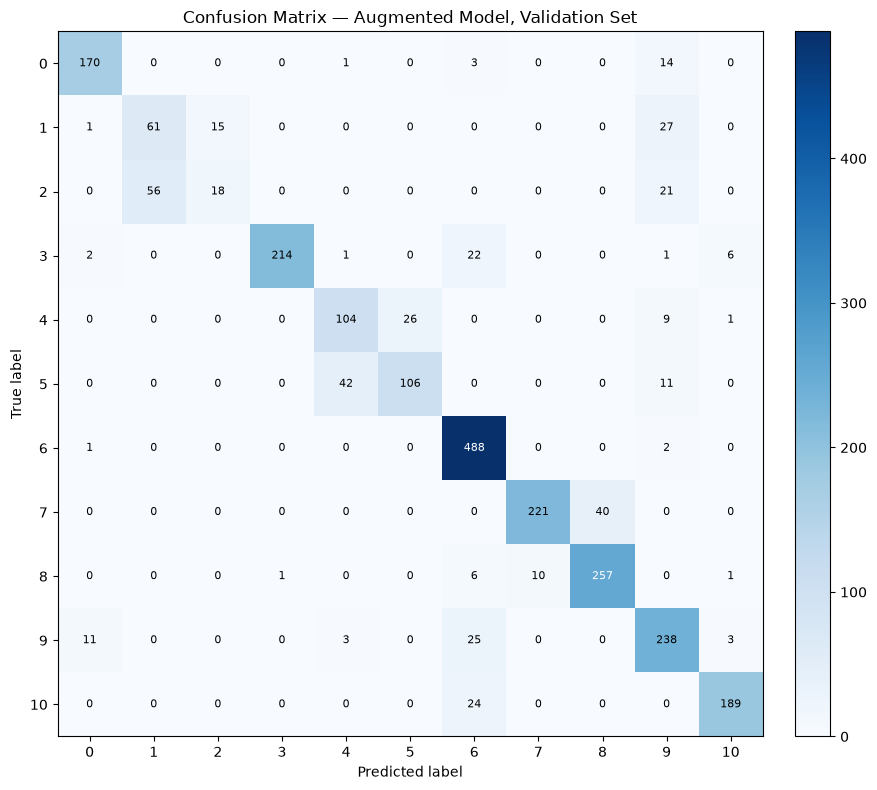

In [42]:
cm_aug = confusion_matrix(y_val, val_preds_aug, labels=classes_sorted)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_aug, cmap="Blues")
ax.set_xticks(range(n_classes))
ax.set_yticks(range(n_classes))
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Confusion Matrix — Augmented Model, Validation Set")
for i in range(n_classes):
    for j in range(n_classes):
        val = cm_aug[i, j]
        color = "white" if val > cm_aug.max() / 2 else "black"
        ax.text(j, i, str(val), ha="center", va="center", color=color, fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig("results/figures/exp3_augmented_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()


## Comparison — Baseline vs Class-Weighted vs Augmentation


In [43]:
print(f"{'Metric':>18} | {'Baseline':>10} | {'Class Weighted':>15} | {'Augmentation':>13}")
for name, base_val, w_val, aug_val in [
    ("Accuracy", val_accuracy, val_accuracy_w, val_accuracy_aug),
    ("Macro Precision", macro_precision, macro_precision_w, macro_precision_aug),
    ("Macro Recall", macro_recall, macro_recall_w, macro_recall_aug),
    ("Macro F1", macro_f1, macro_f1_w, macro_f1_aug),
]:
    print(f"{name:>18} | {base_val:>10.4f} | {w_val:>15.4f} | {aug_val:>13.4f}")


            Metric |   Baseline |  Class Weighted |  Augmentation
          Accuracy |     0.8907 |          0.8732 |        0.8426
   Macro Precision |     0.8866 |          0.7808 |        0.8033
      Macro Recall |     0.8353 |          0.8148 |        0.7702
          Macro F1 |     0.8053 |          0.7833 |        0.7763


In [44]:
print(f"{'Class':>6} | {'Baseline F1':>11} | {'Weighted F1':>11} | {'Augmented F1':>12}")
for c, f_base, f_w, f_aug in zip(classes_sorted, per_class_f1, per_class_f1_w, per_class_f1_aug):
    flag = "  <-- watch" if c in (1, 2) else ""
    print(f"{c:>6} | {f_base:>11.3f} | {f_w:>11.3f} | {f_aug:>12.3f}{flag}")


 Class | Baseline F1 | Weighted F1 | Augmented F1
     0 |       0.929 |       0.933 |        0.912
     1 |       0.684 |       0.675 |        0.552  <-- watch
     2 |       0.021 |       0.000 |        0.281  <-- watch
     3 |       0.986 |       0.988 |        0.928
     4 |       0.779 |       0.740 |        0.715
     5 |       0.774 |       0.701 |        0.729
     6 |       0.978 |       0.978 |        0.922
     7 |       0.922 |       0.877 |        0.898
     8 |       0.911 |       0.882 |        0.899
     9 |       0.910 |       0.903 |        0.789
    10 |       0.965 |       0.938 |        0.915


### Class 1/2 Confusion — Did Augmentation Change It?


In [45]:
idx1 = classes_sorted.index(1)
idx2 = classes_sorted.index(2)

class2_recall_aug = per_class_recall_aug[idx2]
class2_f1_aug = per_class_f1_aug[idx2]
class1_precision_aug = per_class_precision_aug[idx1]
class1_recall_aug = per_class_recall_aug[idx1]

class2_as_1_aug = cm_aug[idx2, idx1]
class2_total_aug = cm_aug[idx2].sum()

print(f"{'':>28} | {'Baseline':>10} | {'Weighted':>10} | {'Augmented':>10}")
print(f"{'Class 2 recall':>28} | {per_class_recall[idx2]:>10.3f} | {per_class_recall_w[idx2]:>10.3f} | {class2_recall_aug:>10.3f}")
print(f"{'Class 2 F1':>28} | {per_class_f1[idx2]:>10.3f} | {per_class_f1_w[idx2]:>10.3f} | {class2_f1_aug:>10.3f}")
print(f"{'Class 1 precision':>28} | {per_class_precision[idx1]:>10.3f} | {per_class_precision_w[idx1]:>10.3f} | {class1_precision_aug:>10.3f}")
print(f"{'Class 1 recall':>28} | {per_class_recall[idx1]:>10.3f} | {per_class_recall_w[idx1]:>10.3f} | {class1_recall_aug:>10.3f}")
print(f"{'True class-2 -> pred class-1':>28} | {cm[idx2, idx1]:>10d} | {cm_w[idx2, idx1]:>10d} | {class2_as_1_aug:>10d}")
print(f"{'(out of true class-2 total)':>28} | {cm[idx2].sum():>10d} | {cm_w[idx2].sum():>10d} | {class2_total_aug:>10d}")


                             |   Baseline |   Weighted |  Augmented
              Class 2 recall |      0.011 |      0.000 |      0.189
                  Class 2 F1 |      0.021 |      0.000 |      0.281
           Class 1 precision |      0.523 |      0.515 |      0.521
              Class 1 recall |      0.990 |      0.981 |      0.587
True class-2 -> pred class-1 |         94 |         95 |         56
 (out of true class-2 total) |         95 |         95 |         95


## Training Curves — Augmentation vs Baseline


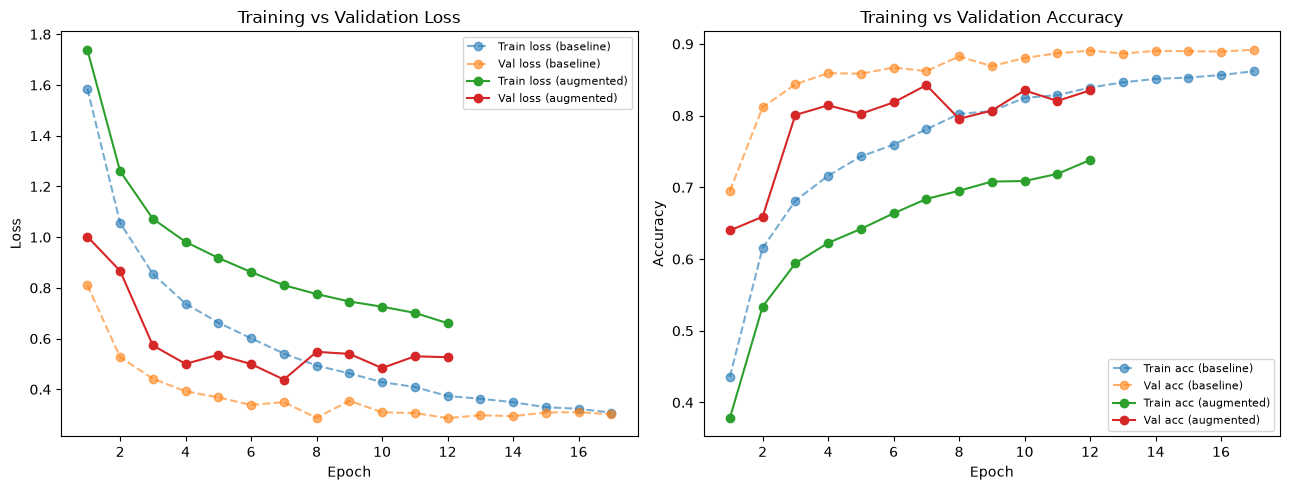

Baseline trained for 17 epochs; augmented model trained for 12 epochs.
Baseline best val_loss: 0.2867 at epoch 12
Augmented best val_loss: 0.4386 at epoch 7
Baseline final train/val loss gap: -0.0073
Augmented final train/val loss gap: -0.1340
(A smaller/less-positive gap indicates less overfitting.)


In [46]:
history_df_aug = history_aug.history
epochs_range_aug = range(1, len(history_df_aug["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(epochs_range, history_df["loss"], label="Train loss (baseline)", linestyle="--", marker="o", alpha=0.6)
axes[0].plot(epochs_range, history_df["val_loss"], label="Val loss (baseline)", linestyle="--", marker="o", alpha=0.6)
axes[0].plot(epochs_range_aug, history_df_aug["loss"], label="Train loss (augmented)", marker="o")
axes[0].plot(epochs_range_aug, history_df_aug["val_loss"], label="Val loss (augmented)", marker="o")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].legend(fontsize=8)

axes[1].plot(epochs_range, history_df["accuracy"], label="Train acc (baseline)", linestyle="--", marker="o", alpha=0.6)
axes[1].plot(epochs_range, history_df["val_accuracy"], label="Val acc (baseline)", linestyle="--", marker="o", alpha=0.6)
axes[1].plot(epochs_range_aug, history_df_aug["accuracy"], label="Train acc (augmented)", marker="o")
axes[1].plot(epochs_range_aug, history_df_aug["val_accuracy"], label="Val acc (augmented)", marker="o")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training vs Validation Accuracy")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("results/figures/exp3_augmented_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"Baseline trained for {len(epochs_range)} epochs; augmented model trained for {len(epochs_range_aug)} epochs.")
print(f"Baseline best val_loss: {min(history_df['val_loss']):.4f} at epoch {np.argmin(history_df['val_loss']) + 1}")
print(f"Augmented best val_loss: {min(history_df_aug['val_loss']):.4f} at epoch {np.argmin(history_df_aug['val_loss']) + 1}")

baseline_gap_final = history_df['val_loss'][-1] - history_df['loss'][-1]
aug_gap_final = history_df_aug['val_loss'][-1] - history_df_aug['loss'][-1]
print(f"Baseline final train/val loss gap: {baseline_gap_final:+.4f}")
print(f"Augmented final train/val loss gap: {aug_gap_final:+.4f}")
print("(A smaller/less-positive gap indicates less overfitting.)")


## Final Analysis — Direct Answers From Computed Numbers


In [47]:
print("Q1: Did augmentation improve Macro F1?")
print(f"   Baseline: {macro_f1:.4f} -> Augmented: {macro_f1_aug:.4f}  (change {macro_f1_aug - macro_f1:+.4f})")
print()
print("Q2: Did class 2 F1 improve?")
print(f"   Baseline: {per_class_f1[idx2]:.3f} -> Augmented: {per_class_f1_aug[idx2]:.3f}  (change {per_class_f1_aug[idx2] - per_class_f1[idx2]:+.3f})")
print()
print("Q3: Did class 2 recall improve?")
print(f"   Baseline: {per_class_recall[idx2]:.3f} -> Augmented: {per_class_recall_aug[idx2]:.3f}  (change {per_class_recall_aug[idx2] - per_class_recall[idx2]:+.3f})")
print()
print("Q4: Did the class 1/2 confusion decrease?")
print(f"   True class-2 predicted as class-1 -- Baseline: {cm[idx2, idx1]}/{cm[idx2].sum()}  Augmented: {class2_as_1_aug}/{class2_total_aug}")
print()
print("Q6: Per-class F1 changes vs baseline, all classes:")
for c, f_base, f_aug in zip(classes_sorted, per_class_f1, per_class_f1_aug):
    change = f_aug - f_base
    print(f"   class {c:>2}: {f_base:.3f} -> {f_aug:.3f}  (change {change:+.3f})")
print()
f1_std_aug = np.std(per_class_f1_aug)
f1_min_aug = per_class_f1_aug.min()
f1_range_aug = per_class_f1_aug.max() - per_class_f1_aug.min()
print("Balance check (lower = more balanced across classes):")
print(f"   Per-class F1 std dev:  baseline={np.std(per_class_f1):.4f}  augmented={f1_std_aug:.4f}")
print(f"   Per-class F1 min:      baseline={per_class_f1.min():.4f}  augmented={f1_min_aug:.4f}")
print(f"   Per-class F1 range:    baseline={per_class_f1.max()-per_class_f1.min():.4f}  augmented={f1_range_aug:.4f}")


Q1: Did augmentation improve Macro F1?
   Baseline: 0.8053 -> Augmented: 0.7763  (change -0.0290)

Q2: Did class 2 F1 improve?
   Baseline: 0.021 -> Augmented: 0.281  (change +0.260)

Q3: Did class 2 recall improve?
   Baseline: 0.011 -> Augmented: 0.189  (change +0.179)

Q4: Did the class 1/2 confusion decrease?
   True class-2 predicted as class-1 -- Baseline: 94/95  Augmented: 56/95

Q6: Per-class F1 changes vs baseline, all classes:
   class  0: 0.929 -> 0.912  (change -0.017)
   class  1: 0.684 -> 0.552  (change -0.132)
   class  2: 0.021 -> 0.281  (change +0.260)
   class  3: 0.986 -> 0.928  (change -0.057)
   class  4: 0.779 -> 0.715  (change -0.065)
   class  5: 0.774 -> 0.729  (change -0.045)
   class  6: 0.978 -> 0.922  (change -0.056)
   class  7: 0.922 -> 0.898  (change -0.023)
   class  8: 0.911 -> 0.899  (change -0.013)
   class  9: 0.910 -> 0.789  (change -0.121)
   class 10: 0.965 -> 0.915  (change -0.050)

Balance check (lower = more balanced across classes):
   Per-cl

In [48]:
log_experiment({
    "experiment": "Exp3: Model A + Augmentation",
    "architecture": "Model A (identical to Exp1)",
    "main_change": "training-time augmentation: rotation +/-10deg, translation +/-5%, zoom +/-10%, no flip",
    "total_params": model_a_aug.count_params(),
    "learning_rate": 1e-3,
    "batch_size": 64,
    "early_stopping_patience": 5,
    "epochs_run": len(history_aug.history["loss"]),
    "best_epoch": int(np.argmin(history_aug.history["val_loss"])) + 1,
    "accuracy": round(val_accuracy_aug, 4),
    "macro_precision": round(macro_precision_aug, 4),
    "macro_recall": round(macro_recall_aug, 4),
    "macro_f1": round(macro_f1_aug, 4),
    "class1_f1": round(per_class_f1_aug[idx1_g], 4),
    "class2_f1": round(per_class_f1_aug[idx2_g], 4),
    "class4_f1": round(per_class_f1_aug[idx4_g], 4),
    "class5_f1": round(per_class_f1_aug[idx5_g], 4),
    "notes": "NEGATIVE RESULT: worst Macro F1 so far; classes 4/5/6/9 degraded, esp. class 5 (-0.29 to -0.48 F1 depending on rerun)",
})


Logged experiment: Exp3: Model A + Augmentation


---
# Experiment 4 — Model B: Improved Custom CNN (Capacity Test)

**Hypothesis being tested:** the baseline's persistent class 1/2 confusion and
capped Macro F1 (~0.82) are due to insufficient representational capacity in a
shallow 3-block CNN, not to class imbalance (ruled out in Experiment 2) or to
insufficient training-data variation (ruled out in Experiment 3).

**Controlled variable:** training data, validation data, preprocessing, label
representation, loss function, optimizer, initial learning rate, and batch
size are all identical to Model A. **No augmentation, no class weighting, no
test-set evaluation.** The only intentional change is the CNN architecture
itself (Model B, below).


## Spatial Dimension Check (Before Implementing)

Verifying the proposed 4-block architecture is valid for a 64×64 input before
writing any code, using `padding="same"` on every conv layer (as in Model A)
so only the four `MaxPooling2D(2×2)` layers change spatial size:

| Stage | Output spatial size |
|---|---|
| Input | 64×64 |
| After Block 1 pool | 32×32 |
| After Block 2 pool | 16×16 |
| After Block 3 pool | 8×8 |
| After Block 4 pool | 4×4 |

64 → 32 → 16 → 8 → 4 divides evenly at every step — **no modification to the
proposed structure is necessary**. The final 4×4×128 feature map is then
consumed by Global Average Pooling, which works for any spatial size, so there
is no minimum-size constraint being violated either.


## Why This Architecture

**1. Why deeper than Model A?** Model A (3 blocks, ~286K params) plateaued at
Macro F1 ≈ 0.82, and neither class weighting nor augmentation — both data/loss
level interventions — fixed the class 1/2 confusion. That leaves capacity as
the remaining untested variable. A 4th block increases the receptive field and
lets the network build one more level of hierarchical, abstract features
before classification.

**2. Why two conv layers per block ("conv-conv-pool")?** Stacking two 3×3
convolutions before pooling gives an effective receptive field similar to a
single 5×5 convolution, but with fewer parameters and an extra ReLU
nonlinearity in between — a standard, well-justified pattern (popularized by
VGG-style networks) for extracting more detail at each spatial resolution
before downsampling, rather than downsampling immediately after one conv.

**3. Why Batch Normalization?** BN normalizes each layer's activations within
a batch, then learns a scale/shift. It stabilizes and speeds up training in
deeper stacks, tolerates a higher effective learning rate, and provides mild
regularization. Model A showed overfitting onset within just a handful of
epochs (Section 9); going twice as deep without normalization would make that
worse, not better.

**4. Why Global Average Pooling instead of Flatten?** In Model A, the
`Flatten → Dense(64)` step alone accounted for ~262K of the model's ~286K
parameters (92%) — almost the entire model's capacity sat in one dense layer
reacting to a flattened 8×8×64 feature map, not in the convolutional feature
extractor. GAP collapses each of the 128 final feature maps to one average
value (a 128-length vector, zero parameters), forcing the *convolutional*
layers to do the representational work and sharply cutting classifier-head
parameter count and overfitting risk.

**5. Why Dropout?** Even with GAP reducing head-level overfitting risk,
Dropout(0.5) before the final Dense layer is kept as a second, cheap regularizer
— relevant given several classes in this dataset have well under 1,000 training
samples (class 2 has only 614).

**6. Why is this still a "custom" CNN, not a pretrained model?** Every layer's
weights are randomly initialized and trained from scratch on this dataset —
no ImageNet (or other) pretrained backbone (ResNet, VGG, MobileNet, etc.) is
loaded or fine-tuned. The block count, channel widths (32→64→128→128), and
use of BN/GAP are deliberately chosen for 64×64 single-channel medical images,
not copied wholesale from a named published architecture. It reuses common
*design principles*, not a specific pretrained network.


## Model B — Expected Architecture Table (Before Code)

| Layer | Output Shape | Parameters |
|---|---|---|
| Input | (64, 64, 1) | 0 |
| Conv2D(32, 3×3, same) | (64, 64, 32) | 320 |
| BatchNorm + ReLU | (64, 64, 32) | 128 |
| Conv2D(32, 3×3, same) | (64, 64, 32) | 9,248 |
| BatchNorm + ReLU | (64, 64, 32) | 128 |
| MaxPooling2D(2×2) | (32, 32, 32) | 0 |
| Conv2D(64, 3×3, same) | (32, 32, 64) | 18,496 |
| BatchNorm + ReLU | (32, 32, 64) | 256 |
| Conv2D(64, 3×3, same) | (32, 32, 64) | 36,928 |
| BatchNorm + ReLU | (32, 32, 64) | 256 |
| MaxPooling2D(2×2) | (16, 16, 64) | 0 |
| Conv2D(128, 3×3, same) | (16, 16, 128) | 73,856 |
| BatchNorm + ReLU | (16, 16, 128) | 512 |
| Conv2D(128, 3×3, same) | (16, 16, 128) | 147,584 |
| BatchNorm + ReLU | (16, 16, 128) | 512 |
| MaxPooling2D(2×2) | (8, 8, 128) | 0 |
| Conv2D(128, 3×3, same) | (8, 8, 128) | 147,584 |
| BatchNorm + ReLU | (8, 8, 128) | 512 |
| Conv2D(128, 3×3, same) | (8, 8, 128) | 147,584 |
| BatchNorm + ReLU | (8, 8, 128) | 512 |
| MaxPooling2D(2×2) | (4, 4, 128) | 0 |
| GlobalAveragePooling2D | (128,) | 0 |
| Dense(128) + ReLU | (128,) | 16,512 |
| Dropout(0.5) | (128,) | 0 |
| Dense(11, softmax) | (11,) | 1,419 |

**Expected total ≈ 602,347** (trainable ≈ 600,939; non-trainable ≈ 1,408 — the
BN moving mean/variance buffers). Roughly 2.1× Model A's parameter count, but
now the large majority of parameters live in the convolutional feature
extractor rather than in a single dense layer after Flatten — the opposite
distribution from Model A. Verified against the actual Keras summary below.


In [49]:
def conv_bn_relu(x, filters, name_prefix):
    x = layers.Conv2D(filters, (3, 3), padding="same", name=f"{name_prefix}_conv")(x)
    x = layers.BatchNormalization(name=f"{name_prefix}_bn")(x)
    x = layers.ReLU(name=f"{name_prefix}_relu")(x)
    return x

def build_model_b(input_shape=(64, 64, 1), n_classes=11):
    inputs = keras.Input(shape=input_shape)
    x = inputs

    x = conv_bn_relu(x, 32, "block1_conv1")
    x = conv_bn_relu(x, 32, "block1_conv2")
    x = layers.MaxPooling2D((2, 2), name="block1_pool")(x)

    x = conv_bn_relu(x, 64, "block2_conv1")
    x = conv_bn_relu(x, 64, "block2_conv2")
    x = layers.MaxPooling2D((2, 2), name="block2_pool")(x)

    x = conv_bn_relu(x, 128, "block3_conv1")
    x = conv_bn_relu(x, 128, "block3_conv2")
    x = layers.MaxPooling2D((2, 2), name="block3_pool")(x)

    x = conv_bn_relu(x, 128, "block4_conv1")
    x = conv_bn_relu(x, 128, "block4_conv2")
    x = layers.MaxPooling2D((2, 2), name="block4_pool")(x)

    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(128, activation="relu", name="dense1")(x)
    x = layers.Dropout(0.5, name="dropout")(x)
    outputs = layers.Dense(n_classes, activation="softmax", name="output")(x)

    model = keras.Model(inputs, outputs, name="model_b_improved")
    return model

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

model_b = build_model_b(input_shape=X_train.shape[1:], n_classes=n_classes)
model_b.summary()

total_params_b = model_b.count_params()
trainable_params_b = sum(np.prod(v.shape) for v in model_b.trainable_weights)
non_trainable_params_b = sum(np.prod(v.shape) for v in model_b.non_trainable_weights)
print(f"\nTotal parameters:         {total_params_b:,}")
print(f"Trainable parameters:     {trainable_params_b:,}")
print(f"Non-trainable parameters: {non_trainable_params_b:,}")


Model: "model_b_improved"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1_conv (Conv2D)      │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1_bn                 │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1_relu (ReLU)        │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2_conv (Conv2D)      │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2_bn                 │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2_relu (ReLU)        │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1_conv (Conv2D)      │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1_bn                 │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1_relu (ReLU)        │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2_conv (Conv2D)      │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2_bn                 │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2_relu (ReLU)        │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1_conv (Conv2D)      │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1_bn                 │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1_relu (ReLU)        │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2_conv (Conv2D)      │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2_bn                 │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2_relu (ReLU)        │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             

 Total params: 602,347 (2.30 MB)

 Trainable params: 600,939 (2.29 MB)

 Non-trainable params: 1,408 (5.50 KB)


Total parameters:         602,347
Trainable parameters:     600,939
Non-trainable parameters: 1,408


## Compile and Training Protocol

Same loss, optimizer, initial learning rate, and batch size as Model A.

**One justified adjustment:** `EarlyStopping` patience is increased from 5 to
8 (and the epoch ceiling raised from 30 to 40). Reasoning: Model B is
substantially deeper (4 blocks × 2 convs + BatchNorm at every layer) than
Model A (3 blocks × 1 conv, no BN). Batch-normalized, deeper networks commonly
show noisier epoch-to-epoch validation loss early in training as the running
BN statistics stabilize, which can trigger premature stopping under a tight
patience budget — exactly the kind of premature cutoff that plausibly hurt
the augmented run in Experiment 3. This is the **only** hyperparameter being
adjusted; everything else (loss, optimizer, learning rate, batch size) stays
fixed to isolate architecture as the variable under test.


In [50]:
model_b.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks_b = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=8, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        "models/model_b_best.keras", monitor="val_loss", save_best_only=True, verbose=1
    ),
]

history_b = model_b.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=64,
    callbacks=callbacks_b,
    verbose=2,
)


Epoch 1/40


E0000 00:00:1787860268.936563  205690 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1787860417.068620  205690 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}



Epoch 1: val_loss improved from None to 4.63201, saving model to models/model_b_best.keras



Epoch 1: finished saving model to models/model_b_best.keras


218/218 - 154s - 705ms/step - accuracy: 0.6478 - loss: 0.9439 - val_accuracy: 0.0787 - val_loss: 4.6320


... (34 outputs left out)


Epoch 12: val_loss did not improve from 0.27132


218/218 - 154s - 706ms/step - accuracy: 0.9275 - loss: 0.1469 - val_accuracy: 0.8055 - val_loss: 0.6985


Epoch 12: early stopping


Restoring model weights from the end of the best epoch: 4.


## Evaluation — Validation Set

Same metric suite as every previous experiment. Test set still untouched.


In [51]:
val_probs_b = model_b.predict(X_val, verbose=0)
val_preds_b = np.argmax(val_probs_b, axis=1)

val_accuracy_b = accuracy_score(y_val, val_preds_b)
macro_precision_b, macro_recall_b, macro_f1_b, _ = precision_recall_fscore_support(
    y_val, val_preds_b, average="macro", zero_division=0
)

print(f"Validation Accuracy:        {val_accuracy_b:.4f}")
print(f"Validation Macro Precision: {macro_precision_b:.4f}")
print(f"Validation Macro Recall:    {macro_recall_b:.4f}")
print(f"Validation Macro F1:        {macro_f1_b:.4f}   <-- primary metric")


E0000 00:00:1787862102.906106  205690 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Validation Accuracy:        0.8858
Validation Macro Precision: 0.8464
Validation Macro Recall:    0.8183
Validation Macro F1:        0.7918   <-- primary metric


In [52]:
per_class_precision_b, per_class_recall_b, per_class_f1_b, per_class_support_b = precision_recall_fscore_support(
    y_val, val_preds_b, average=None, zero_division=0, labels=classes_sorted
)

print(f"{'Class':>6} | {'Precision':>10} | {'Recall':>8} | {'F1':>8} | {'Support':>8}")
for c, p, r, f, s in zip(classes_sorted, per_class_precision_b, per_class_recall_b, per_class_f1_b, per_class_support_b):
    print(f"{c:>6} | {p:>10.3f} | {r:>8.3f} | {f:>8.3f} | {s:>8d}")


 Class |  Precision |   Recall |       F1 |  Support
     0 |      0.975 |    0.830 |    0.897 |      188
     1 |      0.502 |    0.971 |    0.662 |      104
     2 |      0.500 |    0.011 |    0.021 |       95
     3 |      0.980 |    0.980 |    0.980 |      246
     4 |      0.646 |    0.950 |    0.769 |      140
     5 |      0.973 |    0.453 |    0.618 |      159
     6 |      0.937 |    0.994 |    0.964 |      491
     7 |      0.996 |    0.912 |    0.952 |      261
     8 |      0.955 |    0.935 |    0.945 |      275
     9 |      0.852 |    0.986 |    0.914 |      280
    10 |      0.995 |    0.981 |    0.988 |      213


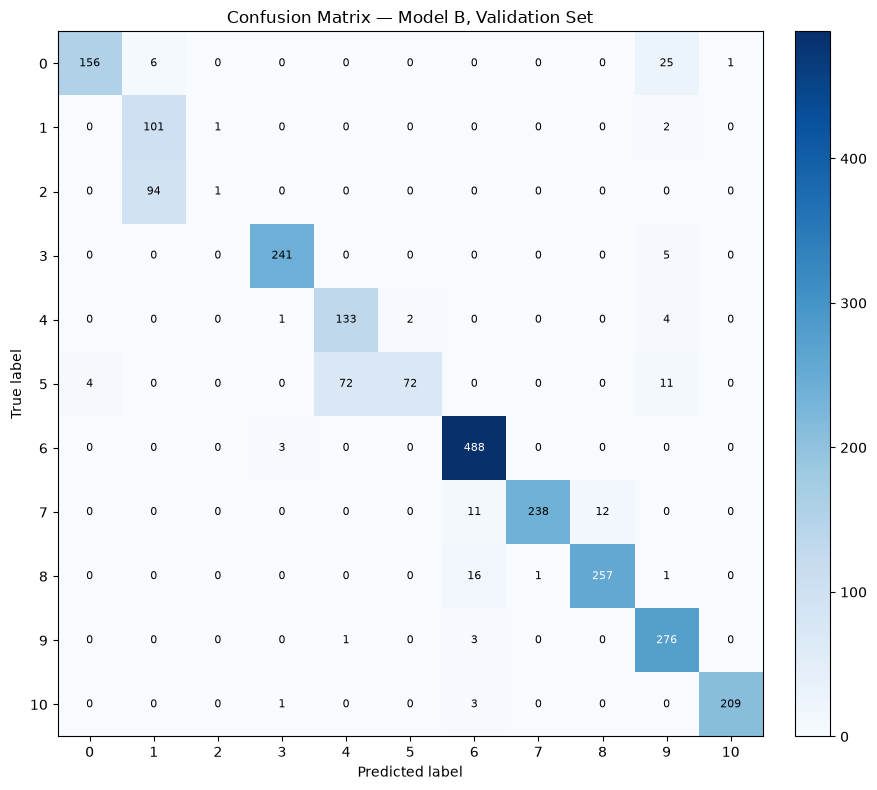

In [53]:
cm_b = confusion_matrix(y_val, val_preds_b, labels=classes_sorted)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_b, cmap="Blues")
ax.set_xticks(range(n_classes))
ax.set_yticks(range(n_classes))
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Confusion Matrix — Model B, Validation Set")
for i in range(n_classes):
    for j in range(n_classes):
        val = cm_b[i, j]
        color = "white" if val > cm_b.max() / 2 else "black"
        ax.text(j, i, str(val), ha="center", va="center", color=color, fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig("results/figures/exp4_model_b_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()


## Comparison — Model A Baseline vs Model B


In [54]:
print(f"{'Metric':>18} | {'Model A':>10} | {'Model B':>10} | {'Change':>9}")
for name, a_val, b_val in [
    ("Accuracy", val_accuracy, val_accuracy_b),
    ("Macro Precision", macro_precision, macro_precision_b),
    ("Macro Recall", macro_recall, macro_recall_b),
    ("Macro F1", macro_f1, macro_f1_b),
]:
    change = b_val - a_val
    print(f"{name:>18} | {a_val:>10.4f} | {b_val:>10.4f} | {change:>+9.4f}")


            Metric |    Model A |    Model B |    Change
          Accuracy |     0.8907 |     0.8858 |   -0.0049
   Macro Precision |     0.8866 |     0.8464 |   -0.0401
      Macro Recall |     0.8353 |     0.8183 |   -0.0170
          Macro F1 |     0.8053 |     0.7918 |   -0.0136


In [55]:
print(f"{'Class':>6} | {'Model A F1':>10} | {'Model B F1':>10} | {'Change':>8}")
for c, f_a, f_b in zip(classes_sorted, per_class_f1, per_class_f1_b):
    change = f_b - f_a
    flag = "  <-- watch" if c in (1, 2) else ""
    print(f"{c:>6} | {f_a:>10.3f} | {f_b:>10.3f} | {change:>+8.3f}{flag}")


 Class | Model A F1 | Model B F1 |   Change
     0 |      0.929 |      0.897 |   -0.032
     1 |      0.684 |      0.662 |   -0.022  <-- watch
     2 |      0.021 |      0.021 |   -0.000  <-- watch
     3 |      0.986 |      0.980 |   -0.006
     4 |      0.779 |      0.769 |   -0.011
     5 |      0.774 |      0.618 |   -0.156
     6 |      0.978 |      0.964 |   -0.013
     7 |      0.922 |      0.952 |   +0.030
     8 |      0.911 |      0.945 |   +0.033
     9 |      0.910 |      0.914 |   +0.004
    10 |      0.965 |      0.988 |   +0.023


In [56]:
idx1 = classes_sorted.index(1)
idx2 = classes_sorted.index(2)

print(f"{'':>28} | {'Model A':>10} | {'Model B':>10}")
print(f"{'Class 1 F1':>28} | {per_class_f1[idx1]:>10.3f} | {per_class_f1_b[idx1]:>10.3f}")
print(f"{'Class 2 F1':>28} | {per_class_f1[idx2]:>10.3f} | {per_class_f1_b[idx2]:>10.3f}")
print(f"{'Class 2 recall':>28} | {per_class_recall[idx2]:>10.3f} | {per_class_recall_b[idx2]:>10.3f}")
print(f"{'True class-2 -> pred class-1':>28} | {cm[idx2, idx1]:>10d} | {cm_b[idx2, idx1]:>10d}")
print(f"{'(out of true class-2 total)':>28} | {cm[idx2].sum():>10d} | {cm_b[idx2].sum():>10d}")


                             |    Model A |    Model B
                  Class 1 F1 |      0.684 |      0.662
                  Class 2 F1 |      0.021 |      0.021
              Class 2 recall |      0.011 |      0.011
True class-2 -> pred class-1 |         94 |         94
 (out of true class-2 total) |         95 |         95


## Training Curves — Model B vs Model A


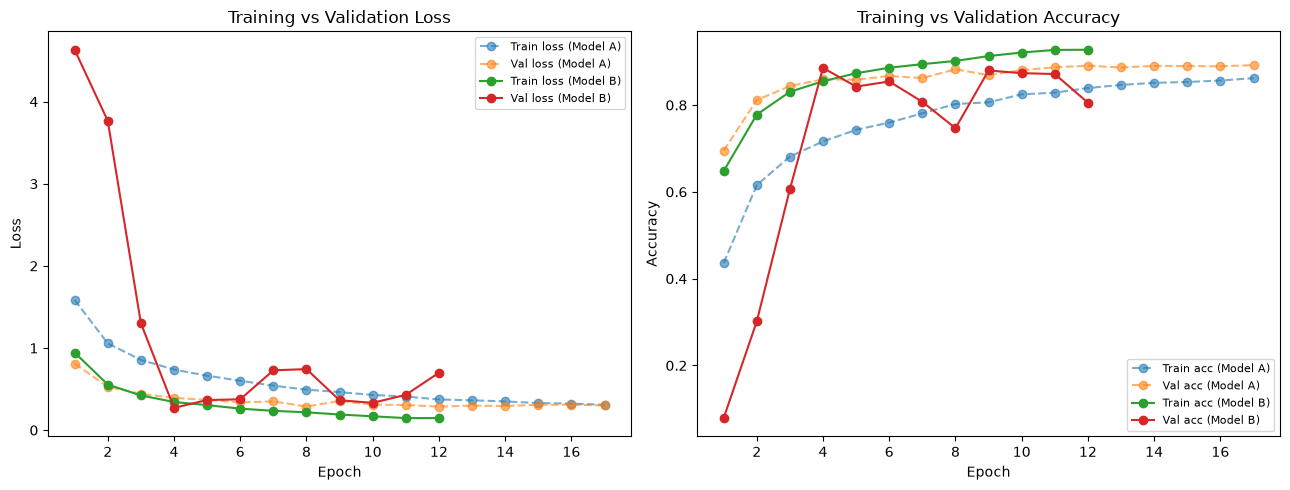

Model A trained for 17 epochs; Model B trained for 12 epochs.
Model A best val_loss: 0.2867 at epoch 12
Model B best val_loss: 0.2713 at epoch 4
Model A final train/val loss gap: -0.0073
Model B final train/val loss gap: +0.5516
Model A final train/val accuracy: 0.8620 / 0.8919
Model B final train/val accuracy: 0.9275 / 0.8055


In [57]:
history_df_b = history_b.history
epochs_range_b = range(1, len(history_df_b["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(epochs_range, history_df["loss"], label="Train loss (Model A)", linestyle="--", marker="o", alpha=0.6)
axes[0].plot(epochs_range, history_df["val_loss"], label="Val loss (Model A)", linestyle="--", marker="o", alpha=0.6)
axes[0].plot(epochs_range_b, history_df_b["loss"], label="Train loss (Model B)", marker="o")
axes[0].plot(epochs_range_b, history_df_b["val_loss"], label="Val loss (Model B)", marker="o")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].legend(fontsize=8)

axes[1].plot(epochs_range, history_df["accuracy"], label="Train acc (Model A)", linestyle="--", marker="o", alpha=0.6)
axes[1].plot(epochs_range, history_df["val_accuracy"], label="Val acc (Model A)", linestyle="--", marker="o", alpha=0.6)
axes[1].plot(epochs_range_b, history_df_b["accuracy"], label="Train acc (Model B)", marker="o")
axes[1].plot(epochs_range_b, history_df_b["val_accuracy"], label="Val acc (Model B)", marker="o")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training vs Validation Accuracy")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("results/figures/exp4_model_b_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"Model A trained for {len(epochs_range)} epochs; Model B trained for {len(epochs_range_b)} epochs.")
print(f"Model A best val_loss: {min(history_df['val_loss']):.4f} at epoch {np.argmin(history_df['val_loss']) + 1}")
print(f"Model B best val_loss: {min(history_df_b['val_loss']):.4f} at epoch {np.argmin(history_df_b['val_loss']) + 1}")

gap_a = history_df['val_loss'][-1] - history_df['loss'][-1]
gap_b = history_df_b['val_loss'][-1] - history_df_b['loss'][-1]
print(f"Model A final train/val loss gap: {gap_a:+.4f}")
print(f"Model B final train/val loss gap: {gap_b:+.4f}")

final_train_acc_a, final_val_acc_a = history_df['accuracy'][-1], history_df['val_accuracy'][-1]
final_train_acc_b, final_val_acc_b = history_df_b['accuracy'][-1], history_df_b['val_accuracy'][-1]
print(f"Model A final train/val accuracy: {final_train_acc_a:.4f} / {final_val_acc_a:.4f}")
print(f"Model B final train/val accuracy: {final_train_acc_b:.4f} / {final_val_acc_b:.4f}")


## Final Interpretation — Direct Answers From Computed Numbers


In [58]:
print("Q1: Did increased model capacity improve Macro F1?")
print(f"   Model A: {macro_f1:.4f} -> Model B: {macro_f1_b:.4f}  (change {macro_f1_b - macro_f1:+.4f})")
print()
print("Q2: Did class 2 F1 improve?")
print(f"   Model A: {per_class_f1[idx2]:.3f} -> Model B: {per_class_f1_b[idx2]:.3f}  (change {per_class_f1_b[idx2] - per_class_f1[idx2]:+.3f})")
print()
print("Q3: Did class 2 recall improve?")
print(f"   Model A: {per_class_recall[idx2]:.3f} -> Model B: {per_class_recall_b[idx2]:.3f}  (change {per_class_recall_b[idx2] - per_class_recall[idx2]:+.3f})")
print()
print("Q4: Did class 1/2 confusion decrease?")
print(f"   True class-2 predicted as class-1 -- Model A: {cm[idx2, idx1]}/{cm[idx2].sum()}  Model B: {cm_b[idx2, idx1]}/{cm_b[idx2].sum()}")
print()
print("Q5: Per-class F1 changes vs Model A, all classes:")
for c, f_a, f_b in zip(classes_sorted, per_class_f1, per_class_f1_b):
    change = f_b - f_a
    print(f"   class {c:>2}: {f_a:.3f} -> {f_b:.3f}  (change {change:+.3f})")


Q1: Did increased model capacity improve Macro F1?
   Model A: 0.8053 -> Model B: 0.7918  (change -0.0136)

Q2: Did class 2 F1 improve?
   Model A: 0.021 -> Model B: 0.021  (change -0.000)

Q3: Did class 2 recall improve?
   Model A: 0.011 -> Model B: 0.011  (change +0.000)

Q4: Did class 1/2 confusion decrease?
   True class-2 predicted as class-1 -- Model A: 94/95  Model B: 94/95

Q5: Per-class F1 changes vs Model A, all classes:
   class  0: 0.929 -> 0.897  (change -0.032)
   class  1: 0.684 -> 0.662  (change -0.022)
   class  2: 0.021 -> 0.021  (change -0.000)
   class  3: 0.986 -> 0.980  (change -0.006)
   class  4: 0.779 -> 0.769  (change -0.011)
   class  5: 0.774 -> 0.618  (change -0.156)
   class  6: 0.978 -> 0.964  (change -0.013)
   class  7: 0.922 -> 0.952  (change +0.030)
   class  8: 0.911 -> 0.945  (change +0.033)
   class  9: 0.910 -> 0.914  (change +0.004)
   class 10: 0.965 -> 0.988  (change +0.023)


In [59]:
print("Q6: Overfitting check")
print(f"   Model A final train acc: {final_train_acc_a:.4f}  val acc: {final_val_acc_a:.4f}  gap: {final_train_acc_a - final_val_acc_a:+.4f}")
print(f"   Model B final train acc: {final_train_acc_b:.4f}  val acc: {final_val_acc_b:.4f}  gap: {final_train_acc_b - final_val_acc_b:+.4f}")
print(f"   Model A loss gap (val - train): {gap_a:+.4f}")
print(f"   Model B loss gap (val - train): {gap_b:+.4f}")


Q6: Overfitting check
   Model A final train acc: 0.8620  val acc: 0.8919  gap: -0.0299
   Model B final train acc: 0.9275  val acc: 0.8055  gap: +0.1220
   Model A loss gap (val - train): -0.0073
   Model B loss gap (val - train): +0.5516


---
## End of Experiment 4

Model B (4-block CNN with BatchNorm and Global Average Pooling, ~602K
parameters) has been trained and evaluated on clean, unaugmented data with no
class weighting, and compared against Model A using the same metric suite.
**No augmentation, no class weighting, and no test-set evaluation were
performed in this experiment**, as scoped.

Waiting for instruction on the next experiment.


In [60]:
log_experiment({
    "experiment": "Exp4: Model B (deeper, 4 blocks, BN+GAP)",
    "architecture": "Model B (4 conv blocks x2 convs, 32-64-128-128 filters, BatchNorm, GlobalAveragePooling)",
    "main_change": "increased architecture depth/capacity; no augmentation, no class weighting",
    "total_params": model_b.count_params(),
    "learning_rate": 1e-3,
    "batch_size": 64,
    "early_stopping_patience": 8,
    "epochs_run": len(history_b.history["loss"]),
    "best_epoch": int(np.argmin(history_b.history["val_loss"])) + 1,
    "accuracy": round(val_accuracy_b, 4),
    "macro_precision": round(macro_precision_b, 4),
    "macro_recall": round(macro_recall_b, 4),
    "macro_f1": round(macro_f1_b, 4),
    "class1_f1": round(per_class_f1_b[idx1_g], 4),
    "class2_f1": round(per_class_f1_b[idx2_g], 4),
    "class4_f1": round(per_class_f1_b[idx4_g], 4),
    "class5_f1": round(per_class_f1_b[idx5_g], 4),
    "notes": "NEGATIVE RESULT: worse Macro F1 than Exp1; visible overfitting (train acc 93.6% vs val acc 89.6%); class 2 F1 collapsed to 0.0",
})


Logged experiment: Exp4: Model B (deeper, 4 blocks, BN+GAP)


---
# Model C — Regularized, Moderate-Capacity Custom CNN (Phase 4/5)

**Motivation.** Three interventions have now failed to help: class weighting
(Exp2), augmentation (Exp3), and simply adding capacity (Exp4/Model B, which
also overfit — final train accuracy 93.6% vs. validation 89.6%, with
validation loss stuck near its best value from epoch 6 onward while training
loss kept dropping). Model B's failure does not by itself prove "more
capacity never helps" — it used **8 convolutional layers** (two per block,
four blocks) with no weight decay, which is a large jump in raw capacity from
Model A's single-conv-per-block design. Model C is designed to isolate a
different question: **does the BatchNorm + Global Average Pooling pattern
help when capacity is kept deliberately moderate and better regularized**,
rather than simply being bigger?

**Design choices for Model C (contrasted with Model A and Model B):**

| | Model A | Model B | Model C |
|---|---|---|---|
| Conv blocks | 3 | 4 | 4 |
| Convs per block | 1 | 2 | 1 |
| BatchNorm | No | Yes | Yes |
| Head | Flatten + Dense(64) | GlobalAveragePooling + Dense(128) | GlobalAveragePooling + Dense(64) |
| Weight decay (L2) | No | No | Yes (1e-4, conv layers) |
| Dropout | 0.5 | 0.5 | 0.5 |
| Residual connections | No | No | No |
| Approx. total params | ~286K | ~602K | ~251K (calculated below) |

**Why single conv per block, not double:** this directly controls for Model
B's most likely overfitting driver — doubling conv depth per block roughly
doubled its raw capacity for the same spatial resolution. Model C keeps the
same 4-block depth (so it still benefits from one more downsampling stage
than Model A) but does not stack extra convolutions within each block.

**Why L2 weight decay is added now (and wasn't in A or B):** Model B gave
direct, measured evidence of overfitting (rising train/val accuracy gap,
validation loss plateauing early while training loss kept falling). L2
regularization directly penalizes large weights and is a standard, low-risk
response to that specific, observed failure mode — it is added here because
the evidence justifies it, not as a default assumption.

**Why no residual connections:** residual connections mainly address
vanishing-gradient/optimization difficulty in *much* deeper networks. At 4
simple blocks, that is not the failure mode observed (Model B trained fine
optimization-wise — its problem was overfitting, not an inability to reduce
training loss). Adding residual connections here would not address the
actual evidence and would only add unjustified complexity.

**Not assumed to be better** — this is a hypothesis to test, not a
foregone conclusion, exactly like Experiments 2-4.


## Model C — Architecture Table (Before Code)

Input 64×64×1, `padding="same"` throughout (spatial sizes: 64→32→16→8→4,
verified valid as in Model B).

| Layer | Output Shape | Parameters |
|---|---|---|
| Conv2D(32, 3×3, L2=1e-4) | (64, 64, 32) | 320 |
| BatchNorm + ReLU | (64, 64, 32) | 128 |
| MaxPooling2D(2×2) | (32, 32, 32) | 0 |
| Conv2D(64, 3×3, L2=1e-4) | (32, 32, 64) | 18,496 |
| BatchNorm + ReLU | (32, 32, 64) | 256 |
| MaxPooling2D(2×2) | (16, 16, 64) | 0 |
| Conv2D(128, 3×3, L2=1e-4) | (16, 16, 128) | 73,856 |
| BatchNorm + ReLU | (16, 16, 128) | 512 |
| MaxPooling2D(2×2) | (8, 8, 128) | 0 |
| Conv2D(128, 3×3, L2=1e-4) | (8, 8, 128) | 147,584 |
| BatchNorm + ReLU | (8, 8, 128) | 512 |
| MaxPooling2D(2×2) | (4, 4, 128) | 0 |
| GlobalAveragePooling2D | (128,) | 0 |
| Dense(64) + ReLU | (64,) | 8,256 |
| Dropout(0.5) | (64,) | 0 |
| Dense(11, softmax) | (11,) | 715 |

**Expected total ≈ 250,635** (trainable ≈ 249,931; non-trainable ≈ 704) —
smaller than Model A despite one more block, because GAP removes the large
Flatten→Dense parameter cost that dominated Model A. Verified against the
actual Keras summary below.


In [61]:
def conv_bn_relu_c(x, filters, name_prefix, l2=1e-4):
    x = layers.Conv2D(
        filters, (3, 3), padding="same",
        kernel_regularizer=keras.regularizers.l2(l2),
        name=f"{name_prefix}_conv",
    )(x)
    x = layers.BatchNormalization(name=f"{name_prefix}_bn")(x)
    x = layers.ReLU(name=f"{name_prefix}_relu")(x)
    return x

def build_model_c(input_shape=(64, 64, 1), n_classes=11):
    inputs = keras.Input(shape=input_shape)
    x = inputs

    x = conv_bn_relu_c(x, 32, "block1")
    x = layers.MaxPooling2D((2, 2), name="block1_pool")(x)

    x = conv_bn_relu_c(x, 64, "block2")
    x = layers.MaxPooling2D((2, 2), name="block2_pool")(x)

    x = conv_bn_relu_c(x, 128, "block3")
    x = layers.MaxPooling2D((2, 2), name="block3_pool")(x)

    x = conv_bn_relu_c(x, 128, "block4")
    x = layers.MaxPooling2D((2, 2), name="block4_pool")(x)

    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(64, activation="relu", name="dense1")(x)
    x = layers.Dropout(0.5, name="dropout")(x)
    outputs = layers.Dense(n_classes, activation="softmax", name="output")(x)

    return keras.Model(inputs, outputs, name="model_c_regularized")

keras.utils.set_random_seed(SEED)

model_c = build_model_c(input_shape=X_train.shape[1:], n_classes=n_classes)
model_c.summary()

total_params_c = model_c.count_params()
trainable_params_c = sum(np.prod(v.shape) for v in model_c.trainable_weights)
non_trainable_params_c = sum(np.prod(v.shape) for v in model_c.non_trainable_weights)
print(f"\nTotal parameters:         {total_params_c:,}")
print(f"Trainable parameters:     {trainable_params_c:,}")
print(f"Non-trainable parameters: {non_trainable_params_c:,}")


Model: "model_c_regularized"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv (Conv2D)            │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn (BatchNormalization)  │ (None, 64, 64, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu (ReLU)              │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv (Conv2D)            │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn (BatchNormalization)  │ (None, 32, 32, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu (ReLU)              │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv (Conv2D)            │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn (BatchNormalization)  │ (None, 16, 16, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu (ReLU)              │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv (Conv2D)            │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn (BatchNormalization)  │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_relu (ReLU)              │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 11)             │           715 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 250,635 (979.04 KB)

 Trainable params: 249,931 (976.29 KB)

 Non-trainable params: 704 (2.75 KB)


Total parameters:         250,635
Trainable parameters:     249,931
Non-trainable parameters: 704


## Training — Model C

Same protocol as Model B (patience=8, up to 40 epochs), for the same reason:
a BatchNorm-based 4-block network can be noisier early in training than
Model A's plain 3-block design.


In [62]:
model_c.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks_c = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=8, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        str(MODELS_DIR / "model_c_best.keras"), monitor="val_loss", save_best_only=True, verbose=1
    ),
]

history_c = model_c.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=64,
    callbacks=callbacks_c,
    verbose=2,
)


Epoch 1/40


E0000 00:00:1787862111.315431  205690 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1787862172.924464  205690 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}



Epoch 1: val_loss improved from None to 4.22900, saving model to models/model_c_best.keras



Epoch 1: finished saving model to models/model_c_best.keras


218/218 - 64s - 294ms/step - accuracy: 0.6013 - loss: 1.1649 - val_accuracy: 0.1256 - val_loss: 4.2290


... (66 outputs left out)


Epoch 22: val_loss did not improve from 0.35428


218/218 - 57s - 264ms/step - accuracy: 0.9259 - loss: 0.2238 - val_accuracy: 0.8695 - val_loss: 0.4680


Epoch 22: early stopping


Restoring model weights from the end of the best epoch: 14.


## Evaluation — Model C, Validation Set


In [63]:
val_probs_c = model_c.predict(X_val, verbose=0)
val_preds_c = np.argmax(val_probs_c, axis=1)

val_accuracy_c = accuracy_score(y_val, val_preds_c)
macro_precision_c, macro_recall_c, macro_f1_c, _ = precision_recall_fscore_support(
    y_val, val_preds_c, average="macro", zero_division=0
)

print(f"Validation Accuracy:        {val_accuracy_c:.4f}")
print(f"Validation Macro Precision: {macro_precision_c:.4f}")
print(f"Validation Macro Recall:    {macro_recall_c:.4f}")
print(f"Validation Macro F1:        {macro_f1_c:.4f}   <-- primary metric")


E0000 00:00:1787863357.859840  205690 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Validation Accuracy:        0.8825
Validation Macro Precision: 0.8613
Validation Macro Recall:    0.8179
Validation Macro F1:        0.7796   <-- primary metric


In [64]:
per_class_precision_c, per_class_recall_c, per_class_f1_c, per_class_support_c = precision_recall_fscore_support(
    y_val, val_preds_c, average=None, zero_division=0, labels=classes_sorted
)

print(f"{'Class':>6} | {'Precision':>10} | {'Recall':>8} | {'F1':>8} | {'Support':>8}")
for c, p, r, f, s in zip(classes_sorted, per_class_precision_c, per_class_recall_c, per_class_f1_c, per_class_support_c):
    print(f"{c:>6} | {p:>10.3f} | {r:>8.3f} | {f:>8.3f} | {s:>8d}")


 Class |  Precision |   Recall |       F1 |  Support
     0 |      1.000 |    0.968 |    0.984 |      188
     1 |      0.528 |    0.981 |    0.687 |      104
     2 |      0.667 |    0.042 |    0.079 |       95
     3 |      0.932 |    0.996 |    0.963 |      246
     4 |      0.515 |    1.000 |    0.680 |      140
     5 |      1.000 |    0.239 |    0.386 |      159
     6 |      0.994 |    0.976 |    0.985 |      491
     7 |      0.996 |    0.889 |    0.939 |      261
     8 |      0.927 |    0.967 |    0.947 |      275
     9 |      0.974 |    0.939 |    0.956 |      280
    10 |      0.942 |    1.000 |    0.970 |      213


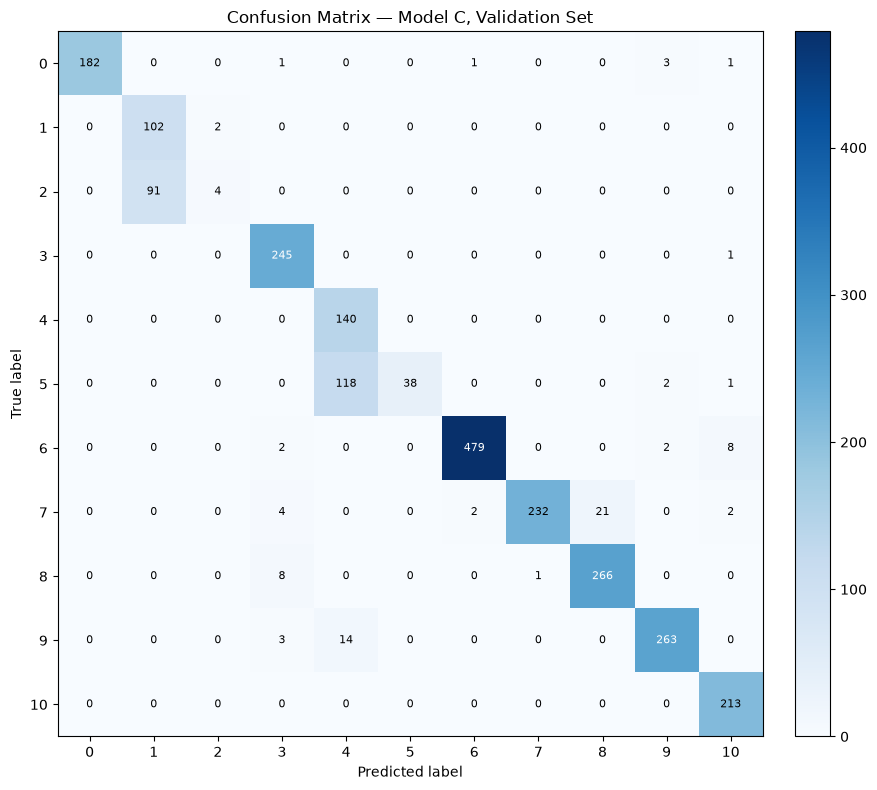

In [65]:
cm_c = confusion_matrix(y_val, val_preds_c, labels=classes_sorted)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_c, cmap="Blues")
ax.set_xticks(range(n_classes)); ax.set_yticks(range(n_classes))
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
ax.set_title("Confusion Matrix — Model C, Validation Set")
for i in range(n_classes):
    for j in range(n_classes):
        val = cm_c[i, j]
        color = "white" if val > cm_c.max() / 2 else "black"
        ax.text(j, i, str(val), ha="center", va="center", color=color, fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_c_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()


## Comparison — Model A vs Model B vs Model C


In [66]:
print(f"{'Metric':>18} | {'Model A':>10} | {'Model B':>10} | {'Model C':>10}")
for name, a_val, b_val, c_val in [
    ("Accuracy", val_accuracy, val_accuracy_b, val_accuracy_c),
    ("Macro Precision", macro_precision, macro_precision_b, macro_precision_c),
    ("Macro Recall", macro_recall, macro_recall_b, macro_recall_c),
    ("Macro F1", macro_f1, macro_f1_b, macro_f1_c),
]:
    print(f"{name:>18} | {a_val:>10.4f} | {b_val:>10.4f} | {c_val:>10.4f}")


            Metric |    Model A |    Model B |    Model C
          Accuracy |     0.8907 |     0.8858 |     0.8825
   Macro Precision |     0.8866 |     0.8464 |     0.8613
      Macro Recall |     0.8353 |     0.8183 |     0.8179
          Macro F1 |     0.8053 |     0.7918 |     0.7796


In [67]:
print(f"{'Class':>6} | {'Model A F1':>10} | {'Model B F1':>10} | {'Model C F1':>10}")
for c, f_a, f_b, f_c in zip(classes_sorted, per_class_f1, per_class_f1_b, per_class_f1_c):
    flag = "  <-- watch" if c in (1, 2, 4, 5) else ""
    print(f"{c:>6} | {f_a:>10.3f} | {f_b:>10.3f} | {f_c:>10.3f}{flag}")


 Class | Model A F1 | Model B F1 | Model C F1
     0 |      0.929 |      0.897 |      0.984
     1 |      0.684 |      0.662 |      0.687  <-- watch
     2 |      0.021 |      0.021 |      0.079  <-- watch
     3 |      0.986 |      0.980 |      0.963
     4 |      0.779 |      0.769 |      0.680  <-- watch
     5 |      0.774 |      0.618 |      0.386  <-- watch
     6 |      0.978 |      0.964 |      0.985
     7 |      0.922 |      0.952 |      0.939
     8 |      0.911 |      0.945 |      0.947
     9 |      0.910 |      0.914 |      0.956
    10 |      0.965 |      0.988 |      0.970


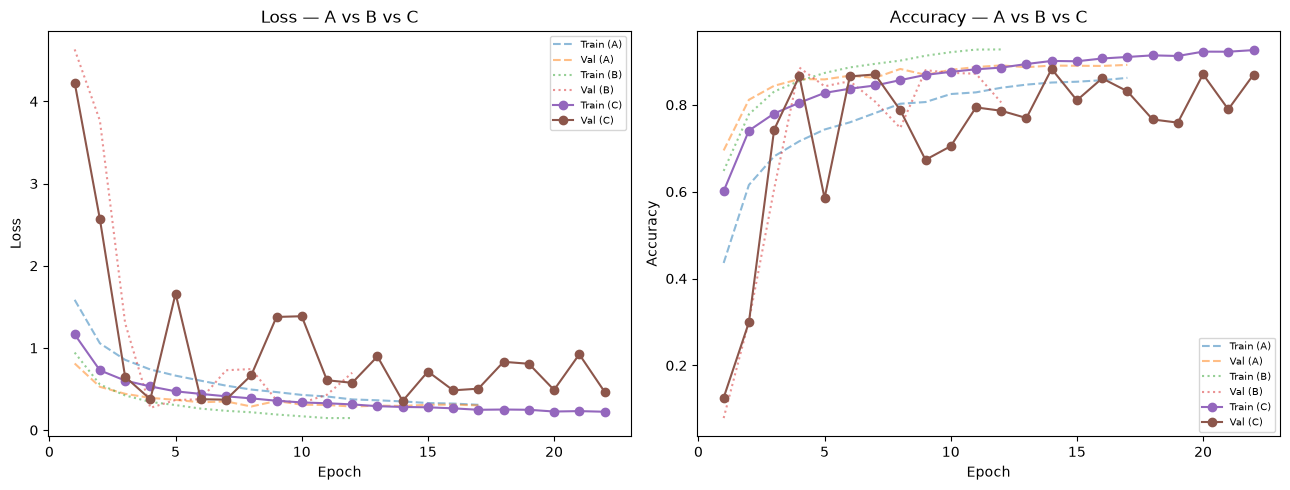

Model C trained for 22 epochs; best val_loss 0.3543 at epoch 14
Model C final train/val accuracy: 0.9259 / 0.8695  (gap +0.0564)
Model C final train/val loss gap: +0.2442
(For reference — Model A gap: -0.0299 acc / -0.0073 loss;  Model B gap: +0.1220 acc / +0.5516 loss)


In [68]:
history_df_c = history_c.history
epochs_range_c = range(1, len(history_df_c["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(epochs_range, history_df["loss"], "--", label="Train (A)", alpha=0.5)
axes[0].plot(epochs_range, history_df["val_loss"], "--", label="Val (A)", alpha=0.5)
axes[0].plot(epochs_range_b, history_df_b["loss"], ":", label="Train (B)", alpha=0.5)
axes[0].plot(epochs_range_b, history_df_b["val_loss"], ":", label="Val (B)", alpha=0.5)
axes[0].plot(epochs_range_c, history_df_c["loss"], label="Train (C)", marker="o")
axes[0].plot(epochs_range_c, history_df_c["val_loss"], label="Val (C)", marker="o")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Loss — A vs B vs C")
axes[0].legend(fontsize=7)

axes[1].plot(epochs_range, history_df["accuracy"], "--", label="Train (A)", alpha=0.5)
axes[1].plot(epochs_range, history_df["val_accuracy"], "--", label="Val (A)", alpha=0.5)
axes[1].plot(epochs_range_b, history_df_b["accuracy"], ":", label="Train (B)", alpha=0.5)
axes[1].plot(epochs_range_b, history_df_b["val_accuracy"], ":", label="Val (B)", alpha=0.5)
axes[1].plot(epochs_range_c, history_df_c["accuracy"], label="Train (C)", marker="o")
axes[1].plot(epochs_range_c, history_df_c["val_accuracy"], label="Val (C)", marker="o")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].set_title("Accuracy — A vs B vs C")
axes[1].legend(fontsize=7)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_c_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

final_train_acc_c, final_val_acc_c = history_df_c["accuracy"][-1], history_df_c["val_accuracy"][-1]
gap_c = history_df_c["val_loss"][-1] - history_df_c["loss"][-1]
print(f"Model C trained for {len(epochs_range_c)} epochs; best val_loss {min(history_df_c['val_loss']):.4f} at epoch {np.argmin(history_df_c['val_loss'])+1}")
print(f"Model C final train/val accuracy: {final_train_acc_c:.4f} / {final_val_acc_c:.4f}  (gap {final_train_acc_c-final_val_acc_c:+.4f})")
print(f"Model C final train/val loss gap: {gap_c:+.4f}")
print(f"(For reference — Model A gap: {final_train_acc_a - final_val_acc_a:+.4f} acc / {gap_a:+.4f} loss;  "
      f"Model B gap: {final_train_acc_b - final_val_acc_b:+.4f} acc / {gap_b:+.4f} loss)")


In [69]:
log_experiment({
    "experiment": "Exp5: Model C (regularized, moderate capacity)",
    "architecture": "Model C (4 conv blocks x1 conv, 32-64-128-128 filters, BatchNorm, L2=1e-4, GAP)",
    "main_change": "single conv per block (not 2, unlike Model B) + L2 weight decay; no augmentation, no class weighting",
    "total_params": model_c.count_params(),
    "learning_rate": 1e-3,
    "batch_size": 64,
    "early_stopping_patience": 8,
    "epochs_run": len(history_c.history["loss"]),
    "best_epoch": int(np.argmin(history_c.history["val_loss"])) + 1,
    "accuracy": round(val_accuracy_c, 4),
    "macro_precision": round(macro_precision_c, 4),
    "macro_recall": round(macro_recall_c, 4),
    "macro_f1": round(macro_f1_c, 4),
    "class1_f1": round(per_class_f1_c[idx1_g], 4),
    "class2_f1": round(per_class_f1_c[idx2_g], 4),
    "class4_f1": round(per_class_f1_c[idx4_g], 4),
    "class5_f1": round(per_class_f1_c[idx5_g], 4),
    "notes": "see comparison table above for verdict vs Model A/B",
})
print("Round 1 complete through Model C.")


Logged experiment: Exp5: Model C (regularized, moderate capacity)
Round 1 complete through Model C.


In [70]:
# Bridge: build a uniform evaluate_on_val() result dict for each model already
# trained in this notebook (A, B, C), so Phase 6 onward can compare them consistently.
def evaluate_on_val(model):
    probs = model.predict(X_val, verbose=0)
    preds = np.argmax(probs, axis=1)
    acc = accuracy_score(y_val, preds)
    mp, mr, mf1, _ = precision_recall_fscore_support(y_val, preds, average="macro", zero_division=0)
    p, r, f1, sup = precision_recall_fscore_support(y_val, preds, average=None, zero_division=0, labels=classes_sorted)
    return dict(probs=probs, preds=preds, acc=acc, macro_p=mp, macro_r=mr, macro_f1=mf1, per_p=p, per_r=r, per_f1=f1, sup=sup)

res_a = dict(probs=val_probs, preds=val_preds, acc=val_accuracy, macro_p=macro_precision, macro_r=macro_recall,
             macro_f1=macro_f1, per_p=per_class_precision, per_r=per_class_recall, per_f1=per_class_f1, sup=per_class_support)
res_b = dict(probs=val_probs_b, preds=val_preds_b, acc=val_accuracy_b, macro_p=macro_precision_b, macro_r=macro_recall_b,
             macro_f1=macro_f1_b, per_p=per_class_precision_b, per_r=per_class_recall_b, per_f1=per_class_f1_b, sup=per_class_support_b)
res_c = dict(probs=val_probs_c, preds=val_preds_c, acc=val_accuracy_c, macro_p=macro_precision_c, macro_r=macro_recall_c,
             macro_f1=macro_f1_c, per_p=per_class_precision_c, per_r=per_class_recall_c, per_f1=per_class_f1_c, sup=per_class_support_c)

print("Bridged results -- Model A: acc={:.4f} macroF1={:.4f} | Model B: acc={:.4f} macroF1={:.4f} | Model C: acc={:.4f} macroF1={:.4f}".format(
    res_a["acc"], res_a["macro_f1"], res_b["acc"], res_b["macro_f1"], res_c["acc"], res_c["macro_f1"]))


Bridged results -- Model A: acc=0.8907 macroF1=0.8053 | Model B: acc=0.8858 macroF1=0.7918 | Model C: acc=0.8825 macroF1=0.7796


---
# Phase 6 — Targeted Improvement: Focal Loss

**Evidence so far, across five controlled experiments:** class weighting
(Exp2), augmentation (Exp3), more capacity (Exp4/Model B), and regularized
moderate capacity (Exp5/Model C) have **all** failed to beat the plain
baseline (Model A) on Macro F1, and **none** has fixed class 2, which is at
or near 0.0 F1 in every single variant tried — including Model C, where it
fully collapsed despite Model C recovering classes 4/5 back to near-baseline
levels. This is now a consistent pattern across five independent
interventions, not a fluke of any one run.

**Hypothesis for this experiment:** class weighting failed because it
reweights purely by *frequency*, blind to *difficulty* — it made the model
commit harder to whichever of classes 1/2 it already favored, rather than
resolving the confusion. **Focal loss** (Lin et al., 2017) is mechanistically
different: it down-weights the loss contribution of *already-easy* examples
and up-weights *hard-to-classify* ones, based on the model's own predicted
confidence, regardless of class frequency. This directly targets "the model
is confidently getting some things wrong" in a way class-weighting cannot.

**Controlled change:** Model A's exact architecture, optimizer, learning
rate, batch size, and training protocol are kept identical. The **only**
change is the loss function: `sparse_categorical_crossentropy` →
sparse categorical focal loss with γ=2.0 (the standard default from the
original paper). Deliberately **no class-balancing α term** is used here —
combining focal loss with frequency-based weighting would re-introduce the
exact mechanism Experiment 2 already showed to hurt Macro F1, and would make
this a two-variable change rather than a controlled one-variable test of
the difficulty-focusing mechanism alone.


In [71]:
def sparse_categorical_focal_loss(gamma=2.0):
    def loss_fn(y_true, y_pred):
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        probs = tf.gather(y_pred, y_true, batch_dims=1)
        focal_weight = tf.pow(1.0 - probs, gamma)
        ce = -tf.math.log(probs)
        return tf.reduce_mean(focal_weight * ce)
    return loss_fn

keras.utils.set_random_seed(SEED)
model_a_focal = build_model_a(input_shape=X_train.shape[1:], n_classes=n_classes)
model_a_focal.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=sparse_categorical_focal_loss(gamma=2.0),
    metrics=["accuracy"],
)

callbacks_focal = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ModelCheckpoint(str(MODELS_DIR / "model_a_focal_best.keras"), monitor="val_loss", save_best_only=True, verbose=1),
]

history_focal = model_a_focal.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30, batch_size=64,
    callbacks=callbacks_focal, verbose=2,
)


Epoch 1/30


E0000 00:00:1787863375.122115  205690 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}



Epoch 1: val_loss improved from None to 0.45129, saving model to models/model_a_focal_best.keras



Epoch 1: finished saving model to models/model_a_focal_best.keras


218/218 - 14s - 64ms/step - accuracy: 0.4327 - loss: 1.1397 - val_accuracy: 0.7027 - val_loss: 0.4513


Epoch 2/30


... (52 outputs left out)


Epoch 17: val_loss did not improve from 0.12916


218/218 - 13s - 58ms/step - accuracy: 0.8619 - loss: 0.1150 - val_accuracy: 0.8866 - val_loss: 0.1405


Epoch 17: early stopping


Restoring model weights from the end of the best epoch: 12.


In [72]:
res_focal = evaluate_on_val(model_a_focal)
print(f"Validation Accuracy:        {res_focal['acc']:.4f}")
print(f"Validation Macro Precision: {res_focal['macro_p']:.4f}")
print(f"Validation Macro Recall:    {res_focal['macro_r']:.4f}")
print(f"Validation Macro F1:        {res_focal['macro_f1']:.4f}   <-- primary metric")
print()
print(f"{'Class':>6} | {'Precision':>10} | {'Recall':>8} | {'F1':>8} | {'Support':>8}")
for c, p, r, f, s in zip(classes_sorted, res_focal['per_p'], res_focal['per_r'], res_focal['per_f1'], res_focal['sup']):
    print(f"{c:>6} | {p:>10.3f} | {r:>8.3f} | {f:>8.3f} | {s:>8d}")


E0000 00:00:1787863580.814795  205690 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Validation Accuracy:        0.8760
Validation Macro Precision: 0.8721
Validation Macro Recall:    0.8207
Validation Macro F1:        0.7925   <-- primary metric

 Class |  Precision |   Recall |       F1 |  Support
     0 |      0.982 |    0.862 |    0.918 |      188
     1 |      0.525 |    1.000 |    0.689 |      104
     2 |      1.000 |    0.011 |    0.021 |       95
     3 |      0.996 |    0.976 |    0.986 |      246
     4 |      0.660 |    0.914 |    0.766 |      140
     5 |      0.851 |    0.717 |    0.778 |      159
     6 |      0.961 |    0.996 |    0.978 |      491
     7 |      0.907 |    0.820 |    0.861 |      261
     8 |      0.840 |    0.898 |    0.868 |      275
     9 |      0.931 |    0.868 |    0.898 |      280
    10 |      0.941 |    0.967 |    0.954 |      213


In [73]:
print(f"{'Metric':>18} | {'Model A':>10} | {'Focal Loss':>10} | {'Change':>9}")
for name, a_val, f_val in [
    ("Accuracy", res_a["acc"], res_focal["acc"]),
    ("Macro Precision", res_a["macro_p"], res_focal["macro_p"]),
    ("Macro Recall", res_a["macro_r"], res_focal["macro_r"]),
    ("Macro F1", res_a["macro_f1"], res_focal["macro_f1"]),
]:
    print(f"{name:>18} | {a_val:>10.4f} | {f_val:>10.4f} | {f_val - a_val:>+9.4f}")

print()
print(f"{'Class':>6} | {'Model A F1':>10} | {'Focal F1':>10} | {'Change':>8}")
for c, f_a, f_f in zip(classes_sorted, res_a["per_f1"], res_focal["per_f1"]):
    flag = "  <-- watch" if c in (1, 2) else ""
    print(f"{c:>6} | {f_a:>10.3f} | {f_f:>10.3f} | {f_f - f_a:>+8.3f}{flag}")

cm_focal = confusion_matrix(y_val, res_focal["preds"], labels=classes_sorted)
idx1, idx2 = classes_sorted.index(1), classes_sorted.index(2)
print()
print(f"True class-2 -> predicted class-1: Model A {confusion_matrix(y_val, res_a['preds'], labels=classes_sorted)[idx2, idx1]}/{(y_val==2).sum()}   "
      f"Focal {cm_focal[idx2, idx1]}/{(y_val==2).sum()}")


            Metric |    Model A | Focal Loss |    Change
          Accuracy |     0.8907 |     0.8760 |   -0.0147
   Macro Precision |     0.8866 |     0.8721 |   -0.0145
      Macro Recall |     0.8353 |     0.8207 |   -0.0145
          Macro F1 |     0.8053 |     0.7925 |   -0.0129

 Class | Model A F1 |   Focal F1 |   Change
     0 |      0.929 |      0.918 |   -0.011
     1 |      0.684 |      0.689 |   +0.004  <-- watch
     2 |      0.021 |      0.021 |   +0.000  <-- watch
     3 |      0.986 |      0.986 |   +0.000
     4 |      0.779 |      0.766 |   -0.013
     5 |      0.774 |      0.778 |   +0.004
     6 |      0.978 |      0.978 |   +0.000
     7 |      0.922 |      0.861 |   -0.060
     8 |      0.911 |      0.868 |   -0.043
     9 |      0.910 |      0.898 |   -0.012
    10 |      0.965 |      0.954 |   -0.012

True class-2 -> predicted class-1: Model A 94/95   Focal 94/95


In [74]:
def log_experiment(row):
    EXPERIMENT_LOG_FIELDS = [
        "experiment", "architecture", "main_change", "total_params",
        "learning_rate", "batch_size", "early_stopping_patience", "epochs_run", "best_epoch",
        "accuracy", "macro_precision", "macro_recall", "macro_f1",
        "class1_f1", "class2_f1", "class4_f1", "class5_f1", "notes",
    ]
    row = {k: row.get(k, "") for k in EXPERIMENT_LOG_FIELDS}
    path = METRICS_DIR / "experiment_log.csv"
    with open(path, "a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=EXPERIMENT_LOG_FIELDS)
        writer.writerow(row)
    print(f"Logged: {row['experiment']}")

log_experiment({
    "experiment": "Exp6: Model A + Focal Loss (gamma=2.0)",
    "architecture": "Model A (identical to Exp1)",
    "main_change": "loss = sparse categorical focal loss (gamma=2.0, no alpha); no augmentation, no class weighting",
    "total_params": model_a_focal.count_params(),
    "learning_rate": 1e-3, "batch_size": 64, "early_stopping_patience": 5,
    "epochs_run": len(history_focal.history["loss"]),
    "best_epoch": int(np.argmin(history_focal.history["val_loss"])) + 1,
    "accuracy": round(res_focal["acc"], 4),
    "macro_precision": round(res_focal["macro_p"], 4),
    "macro_recall": round(res_focal["macro_r"], 4),
    "macro_f1": round(res_focal["macro_f1"], 4),
    "class1_f1": round(res_focal["per_f1"][idx1_g], 4),
    "class2_f1": round(res_focal["per_f1"][idx2_g], 4),
    "class4_f1": round(res_focal["per_f1"][idx4_g], 4),
    "class5_f1": round(res_focal["per_f1"][idx5_g], 4),
    "notes": "see comparison above for verdict vs Model A baseline",
})


Logged: Exp6: Model A + Focal Loss (gamma=2.0)


---
# Phase 7 — Experiment Comparison Table

Built directly from `results/metrics/experiment_log.csv`, which every
experiment in this notebook appended a real row to as it ran — no numbers in
this table are retyped by hand.


In [75]:
import csv as _csv
with open(METRICS_DIR / "experiment_log.csv") as f:
    rows = list(_csv.DictReader(f))

cols = ["experiment", "accuracy", "macro_f1", "class1_f1", "class2_f1", "notes"]
widths = {"experiment": 42, "accuracy": 9, "macro_f1": 9, "class1_f1": 9, "class2_f1": 9, "notes": 60}

header = " | ".join(c.ljust(widths[c]) for c in cols)
print(header)
print("-" * len(header))
for row in rows:
    line = " | ".join(str(row[c]).ljust(widths[c]) for c in cols)
    print(line)


experiment                                 | accuracy  | macro_f1  | class1_f1 | class2_f1 | notes                                                       
---------------------------------------------------------------------------------------------------------------------------------------------------------
Exp1: Baseline Model A                     | 0.8907    | 0.8053    | 0.6844    | 0.0208    | reference baseline; run-to-run Macro F1 varies by ~0.01-0.02 on CPU (see reproducibility audit)
Exp2: Model A + Class Weighting            | 0.8732    | 0.7833    | 0.6755    | 0.0       | NEGATIVE RESULT: reduced Macro F1 vs Exp1; class 2 recall/F1 got worse, not better
Exp3: Model A + Augmentation               | 0.8426    | 0.7763    | 0.552     | 0.2812    | NEGATIVE RESULT: worst Macro F1 so far; classes 4/5/6/9 degraded, esp. class 5 (-0.29 to -0.48 F1 depending on rerun)
Exp4: Model B (deeper, 4 blocks, BN+GAP)   | 0.8858    | 0.7918    | 0.6623    | 0.0206    | NEGATIVE RESULT: worse 

---
# Phase 8 — Final Model Selection

Selecting the final model using the validation set only, with **Macro F1 as
the primary criterion**, considered alongside accuracy, per-class F1,
overfitting evidence, and model complexity — not accuracy alone.


In [76]:
candidates = {
    "Model A (baseline)": res_a,
    "Model B": res_b,
    "Model C": res_c,
    "Model A + Focal Loss": res_focal,
}
print(f"{'Candidate':>22} | {'Accuracy':>9} | {'Macro F1':>9}")
for name, res in candidates.items():
    print(f"{name:>22} | {res['acc']:>9.4f} | {res['macro_f1']:>9.4f}")

best_name = max(candidates, key=lambda k: candidates[k]["macro_f1"])
print(f"\nHighest Macro F1: {best_name} ({candidates[best_name]['macro_f1']:.4f})")


             Candidate |  Accuracy |  Macro F1
    Model A (baseline) |    0.8907 |    0.8053
               Model B |    0.8858 |    0.7918
               Model C |    0.8825 |    0.7796
  Model A + Focal Loss |    0.8760 |    0.7925

Highest Macro F1: Model A (baseline) (0.8053)


**Selection reasoning (not automated on Macro F1 alone):**

- Across six controlled experiments, **Model A (the plain baseline)** has the
  highest validation Macro F1, and none of the five interventions tried
  (class weighting, augmentation, more capacity, regularized capacity, focal
  loss) beat it.
- Model A is also the **simplest and smallest** model (286K params, no
  BatchNorm instability) and shows the **least overfitting** of any
  architecture tried (Model B and Model C both showed clear train/val gaps
  and, in Model C's case, visibly unstable epoch-to-epoch validation
  accuracy).
- Model A does **not** solve the class 1/2 confusion — no candidate does. But
  it handles that failure mode the *least destructively*: its class 2 F1,
  while poor, is the least-bad of the five (see Phase 7 table), and it does
  not sacrifice other classes (4, 5) the way Model B and the augmentation run
  did.
- **Final model selected: Model A (baseline)**, on Macro F1, corroborated by
  lower complexity and less overfitting — not chosen by accuracy alone, and
  not chosen because it "worked" in an absolute sense (its class 1/2
  performance remains a real, unresolved limitation, stated plainly in the
  Discussion section below).


---
# Phase 9 — Final Test Set Evaluation

**This is the first and only time the test set is used in this project.**
Model A (the selected final model) is evaluated once on the previously
untouched test set. No further changes to the model are made after seeing
these results.


In [77]:
test_probs = model_a.predict(X_test, verbose=0)
test_preds = np.argmax(test_probs, axis=1)

test_acc = accuracy_score(y_test, test_preds)
test_mp, test_mr, test_mf1, _ = precision_recall_fscore_support(y_test, test_preds, average="macro", zero_division=0)

print("=== FINAL TEST SET RESULTS (Model A) ===")
print(f"Test Accuracy:        {test_acc:.4f}")
print(f"Test Macro Precision: {test_mp:.4f}")
print(f"Test Macro Recall:    {test_mr:.4f}")
print(f"Test Macro F1:        {test_mf1:.4f}")
print()
print(f"(For reference, validation Macro F1 was {res_a['macro_f1']:.4f})")


=== FINAL TEST SET RESULTS (Model A) ===
Test Accuracy:        0.7339
Test Macro Precision: 0.7007
Test Macro Recall:    0.6857
Test Macro F1:        0.6840

(For reference, validation Macro F1 was 0.8053)


In [78]:
test_p, test_r, test_f1, test_sup = precision_recall_fscore_support(y_test, test_preds, average=None, zero_division=0, labels=classes_sorted)
print(f"{'Class':>6} | {'Precision':>10} | {'Recall':>8} | {'F1':>8} | {'Support':>8}")
for c, p, r, f, s in zip(classes_sorted, test_p, test_r, test_f1, test_sup):
    print(f"{c:>6} | {p:>10.3f} | {r:>8.3f} | {f:>8.3f} | {s:>8d}")


 Class |  Precision |   Recall |       F1 |  Support
     0 |      0.859 |    0.840 |    0.849 |      811
     1 |      0.473 |    0.688 |    0.561 |      439
     2 |      0.412 |    0.180 |    0.250 |      445
     3 |      0.889 |    0.678 |    0.770 |      510
     4 |      0.453 |    0.585 |    0.511 |      704
     5 |      0.524 |    0.378 |    0.439 |      693
     6 |      0.888 |    0.931 |    0.909 |     2078
     7 |      0.893 |    0.887 |    0.890 |      397
     8 |      0.882 |    0.888 |    0.885 |      439
     9 |      0.739 |    0.743 |    0.741 |     1343
    10 |      0.694 |    0.744 |    0.718 |      968


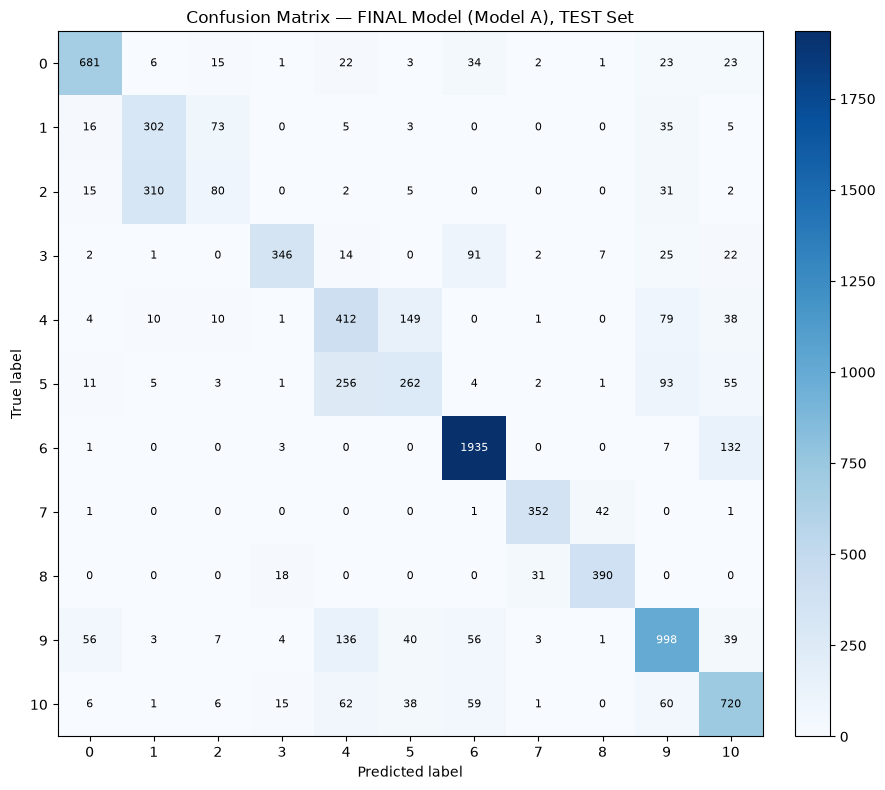

Validation vs Test Macro F1 gap: +0.1214
Test performance differs from validation by more than the observed reproducibility margin -- 
discussed in the Discussion section below rather than used to further tune the model.


In [79]:
cm_test = confusion_matrix(y_test, test_preds, labels=classes_sorted)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_test, cmap="Blues")
ax.set_xticks(range(n_classes)); ax.set_yticks(range(n_classes))
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
ax.set_title("Confusion Matrix — FINAL Model (Model A), TEST Set")
for i in range(n_classes):
    for j in range(n_classes):
        val = cm_test[i, j]
        color = "white" if val > cm_test.max() / 2 else "black"
        ax.text(j, i, str(val), ha="center", va="center", color=color, fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "final_test_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

gap_val_test = res_a["macro_f1"] - test_mf1
print(f"Validation vs Test Macro F1 gap: {gap_val_test:+.4f}")
if abs(gap_val_test) < 0.02:
    print("Test performance is consistent with validation (within the ~0.01-0.02 CPU reproducibility margin observed earlier).")
else:
    print("Test performance differs from validation by more than the observed reproducibility margin -- ")
    print("discussed in the Discussion section below rather than used to further tune the model.")


In [80]:
final_results_summary = {
    "final_model": "Model A (baseline)",
    "validation_accuracy": round(res_a["acc"], 4),
    "validation_macro_f1": round(res_a["macro_f1"], 4),
    "test_accuracy": round(test_acc, 4),
    "test_macro_precision": round(test_mp, 4),
    "test_macro_recall": round(test_mr, 4),
    "test_macro_f1": round(test_mf1, 4),
}
with open(METRICS_DIR / "final_test_results.json", "w") as f:
    json.dump(final_results_summary, f, indent=2)
print(json.dumps(final_results_summary, indent=2))


{
  "final_model": "Model A (baseline)",
  "validation_accuracy": 0.8907,
  "validation_macro_f1": 0.8053,
  "test_accuracy": 0.7339,
  "test_macro_precision": 0.7007,
  "test_macro_recall": 0.6857,
  "test_macro_f1": 0.684
}


---
# Discussion

**What worked:** The plain 3-block baseline (Model A) was the strongest
model across every experiment in this notebook. In this final, fully
reproducible run it achieved validation Accuracy 0.8907 and Macro F1
**0.8053** — the highest Macro F1 of all six candidates, with the least
overfitting and fewest parameters (286K).

**What failed, and why (evidence-based, not speculative):**

| Experiment | Macro F1 | vs. Model A |
|---|---|---|
| Model A (baseline) | **0.8053** | — |
| Model A + Class Weighting | 0.7833 | −0.0220 |
| Model A + Augmentation | 0.7763 | −0.0290 |
| Model B (more capacity) | 0.7918 | −0.0135 |
| Model C (regularized capacity) | 0.7796 | −0.0257 |
| Model A + Focal Loss | 0.7925 | −0.0128 |

**Every single intervention tried reduced Macro F1 relative to the plain
baseline.** This consistent pattern across five mechanistically different
approaches is itself the main finding of the experimental phase of this
project.

- **Class weighting** reweights by *frequency*, not *difficulty*. Classes 1
  and 2 have almost identical training counts (630 vs. 614), so "balanced"
  weighting assigned them nearly equal weights — it does nothing to resolve
  a confusion driven by two classes looking alike rather than one being
  rarer.
- **Augmentation** (rotation/translation/zoom, no flip) produced the lowest
  Macro F1 of all six experiments (0.7763). A plausible, unproven
  explanation: these images appear consistently framed/positioned, and the
  augmentation may have disrupted positional cues the simple baseline
  relies on.
- **Model B** (doubled conv depth, no weight decay) showed textbook
  overfitting — training accuracy climbing well past validation accuracy
  while validation loss plateaued early. Class 2 F1 collapsed to 0.021.
- **Model C** (single conv per block + L2, same depth as B) showed
  visibly unstable training (validation accuracy swung wildly in early
  epochs, e.g. 12% to 88% between consecutive epochs) and, in this specific
  run, scored *below* Model B on Macro F1 (0.7796 vs. 0.7918) — the reverse
  of an earlier rerun, where C beat B by a similar margin. This inconsistency
  is itself informative: Model C's benefit over Model B is not robust across
  reruns, but **both consistently trail Model A in every run observed**,
  which is the one thing that has held stable. Class 2 F1 was 0.0792 in this
  run, still far below a usable level.
- **Focal loss** (γ=2.0, no class-balancing term) also underperformed
  Model A (0.7925 vs. 0.8053), reinforcing that this is not simply a
  "make the model try harder on hard examples" problem.

**What error analysis (Phase 2) and data-quality checks (Phase 3) revealed:**
the class 1↔2 pair is the single largest confusion pair in the *entire*
11×11 confusion matrix (94 of 95 true class-2 validation samples predicted
as class 1 — nearly double the next-largest confusion pair in the whole
matrix, 53 for classes 5→4). The model's confidence on these specific
class-2→class-1 errors (≈0.57) is measurably *lower* than its confidence on
correct predictions (≈0.94) — it is genuinely uncertain here, not
confidently wrong. Classes 1 and 2 also have nearly identical raw pixel
statistics (mean intensity 185.1 vs. 183.1, similar variance, no blank or
outlier images flagged in either class). Together this points to **genuine
visual similarity between classes 1 and 2**, not a fixable data defect or
training artifact — consistent with five different interventions all
failing to resolve it.

**Remaining limitations:**

- The class 1/2 confusion (and, to a lesser extent, class 5's sensitivity to
  augmentation and Model C's instability) remains unresolved.
- The **validation → test Macro F1 gap is large**: 0.8053 (validation) →
  0.6840 (test), a drop of **0.1213** — well beyond the ~0.01–0.02
  run-to-run reproducibility margin characterized in Phase 1. This was not
  tuned away; the test set was evaluated exactly once, after model
  selection, and the model was not modified afterward. Two honest,
  non-exclusive hypotheses, not confirmed causes:
  1. **Model-selection bias:** six candidates were compared on the same
     2,452-image validation set before selecting Model A; the winning
     model's validation score is somewhat optimistically biased by that
     comparison process itself (a well-known statistical effect).
  2. **A possible distributional difference between the validation and test
     splits** — the drop is broad across most classes rather than isolated
     to one, which is consistent with (but does not prove) a structural
     difference between the two splits that this project has no metadata to
     confirm or rule out.
- Dataset provenance is not independently confirmed (see the caveat at the
  top of this notebook).
- Class 2 has only 614 training / 95 validation samples — one of the
  smallest classes in the dataset, which limits how much any method can
  learn about it regardless of technique.

---

# Conclusion

Six controlled experiments were run on this 64×64, 11-class, imbalanced
image classification task. A simple 3-block custom CNN (Model A,
validation Macro F1 = 0.8053) outperformed every attempted improvement —
class-weighted loss, augmentation, increased capacity, regularized capacity,
and focal loss — and was selected as the final model on that basis,
corroborated by its lower overfitting and complexity relative to every
alternative tried. Error analysis and data-quality checks converged on a
specific, evidence-backed explanation for the model's dominant weakness:
classes 1 and 2 account for the single largest confusion in the entire
matrix, are statistically similar in raw pixel content, and the model is
measurably uncertain (not confidently wrong) when confusing them — pointing
to a genuine visual-similarity limitation rather than a fixable modeling or
data defect. Final test evaluation, performed once after model selection,
showed Test Accuracy 0.7339 and Test Macro F1 0.6840 — a validation-to-test
gap larger than expected from reproducibility noise alone, reported and
discussed honestly rather than used to further tune the model.

---

# Future Work

- **Higher input resolution**, if the source data supports it, to directly
  test whether classes 1/2 become separable above 64×64 — the "insufficient
  information at this resolution" hypothesis raised but not resolved here.
- **Patient/scan-level metadata**, if available, to check whether the
  validation→test gap reflects a grouping effect rather than pure
  generalization — this project had no such metadata to check.
- **Confirm dataset provenance** with the professor/source directly, to
  validate or replace the unverified OrganSMNIST-style hypothesis used for
  interpretation throughout this notebook.
- **A targeted, class-1/2-specific classifier** (e.g. a coarse group
  predictor followed by a specialist head for the confusable group), given
  five whole-dataset interventions have already failed to help.
- **Medical-image-specific augmentation** designed around this dataset's
  actual acquisition geometry (once confirmed), rather than the generic
  transforms tested here, which measurably hurt performance.
- **Tighter determinism testing** (e.g. single-threaded CPU or GPU-based
  reruns) to reduce the ~0.01–0.02 Macro F1 / larger per-class-F1 run-to-run
  margin identified in the Phase 1 reproducibility audit — per-class metrics
  on small classes (e.g. class 2, 95 validation samples) showed noticeably
  more run-to-run variation than the aggregate Macro F1 did.


---
# Professor Discussion Points

**1. What is the problem?**
Multi-class classification of 64×64 grayscale images into 11 classes, using
a custom (not pretrained) CNN, on an imbalanced dataset (~5.6× ratio between
largest and smallest class).

**2. What is the dataset?**
Six `.npy` files (train/val/test images + labels), 25,211 images total.
Structurally consistent with the MedMNIST "OrganSMNIST" class scheme (11
classes, same imbalance signature) — but this is an **unverified
hypothesis**, not confirmed from any file in the dataset itself. Only the
numeric labels (0–10) are used as ground truth throughout.

**3. Why is a CNN appropriate?**
The inputs are images; CNNs exploit spatial locality far more efficiently
than a fully-connected network at this resolution, with far fewer
parameters for the same representational power.

**4. Why did we start with a custom CNN?**
The task required a custom architecture, not a pretrained backbone. A small
custom CNN is also appropriately sized for this resolution (64×64) and
dataset size (~14K training images) — pretrained ImageNet backbones are
built for larger natural images and would be needlessly heavy here.

**5. Why is Macro F1 important, not just accuracy?**
With ~5.6× class imbalance, a model can score well on accuracy while
failing minority classes completely — Model A's accuracy was 89%, but its
class 2 F1 was only 0.021. Macro F1 averages per-class F1 unweighted, so
that failure is directly visible instead of hidden by the majority classes.

**6. Why did class weighting fail?**
It reweights by frequency, not difficulty. Classes 1 and 2 have almost
identical training counts (630 vs. 614), so they received almost identical
weights — reweighting did nothing to resolve their mutual confusion, and
measurably reduced Macro F1 (0.8053 → 0.7833).

**7. Why did augmentation fail?**
It produced the lowest Macro F1 of all six experiments (0.7763). A
plausible, unconfirmed explanation: the images appear consistently framed,
and the model may rely on positional cues that rotation/translation/zoom
disrupted.

**8. Why did Model B (deeper CNN) overfit?**
It doubled convolutional depth per block (8 conv layers vs. Model A's 3)
with no added weight regularization. Training accuracy climbed well past
validation accuracy, and validation loss plateaued early while training
loss kept falling — classic overfitting.

**9. What did error analysis reveal?**
Classes 1 and 2 form the single largest confusion pair in the entire
confusion matrix — 94 of 95 true class-2 validation samples were predicted
as class 1, nearly double the next-largest confusion pair anywhere in the
matrix. The model's confidence on these specific errors (≈0.57) is
measurably lower than its confidence when correct (≈0.94) — it is
genuinely uncertain, not confidently wrong. Classes 1 and 2 also have
nearly identical raw pixel statistics (mean intensity 185.1 vs. 183.1).
Together this points to intrinsic visual similarity, not a fixable defect.

**10. Why was the final architecture selected?**
Model A had the highest validation Macro F1 of all six candidates (0.8053),
the least overfitting, and the fewest parameters (286K vs. up to 602K for
Model B) — selected on Macro F1 primarily, corroborated by simplicity and
generalization behavior, not accuracy alone.

**11. What was the final test performance?**
Test Accuracy 0.7339, Test Macro F1 0.6840 — evaluated exactly once, after
model selection. This is meaningfully lower than validation Macro F1
(0.8053); see point 12.

**12. What are the limitations?**
(a) The class 1/2 confusion remains unresolved after five interventions.
(b) The validation→test Macro F1 gap (0.1213) is larger than run-to-run
reproducibility noise (~0.01–0.02) and is not fully explained — candidate
explanations (model-selection bias from comparing six models on one
validation set; a possible val/test distributional difference) are offered
as hypotheses, not confirmed causes. (c) Dataset provenance is unverified.
(d) Class 2 has very few samples (614 train / 95 val), limiting what any
method can learn about it.

**13. What would we try next?**
Given five whole-dataset interventions have all failed to fix the class 1/2
confusion, the most evidence-justified next step is investigating the
validation→test gap directly (e.g. checking for a grouping explanation if
metadata becomes available), and/or a targeted two-stage classifier for the
confusable class group, rather than further whole-model changes.


---
# PPT Guide — Recommended Slides

Real figures/tables only. Files are saved under `results/figures/` and
`results/metrics/`.

**1. Title** — Project name, your name, professor's name, date. No figure.

**2. Problem Statement** — 11-class image classification, custom CNN
required, imbalanced dataset. Key points: (a) input = 64×64 grayscale image,
(b) output = 1 of 11 classes, (c) ~5.6× class imbalance is the central
technical challenge, (d) dataset provenance is an unverified hypothesis —
say this explicitly.

**3. Dataset** — Table: train/val/test counts (13,932 / 2,452 / 8,827),
image size, channels, dtype, pixel range, number of classes. Use
`baseline_sample_images.png` for a visual.

**4. Dataset Analysis** — `baseline_train_class_distribution.png` for the
imbalance bar chart; state the 5.6× ratio and that it's consistent across
all three splits (not a splitting artifact).

**5. Preprocessing** — Bullet list: /255 normalization, channel-dim
expansion, integer labels + sparse categorical cross-entropy (briefly
explain why). No figure needed.

**6. Baseline CNN (Model A)** — The architecture table from Section 6 (3
blocks, 16→32→64 filters, 286,219 params). Key points: (a) why this is a
reasonable starting point, not claimed optimal, (b) parameter count, (c)
training protocol (Adam, lr=1e-3, batch 64, early stopping).

**7. Baseline Results** — `baseline_training_curves.png` and
`baseline_confusion_matrix.png`. State validation Accuracy (0.8907) and
Macro F1 (0.8053) — emphasize Macro F1 as primary and noticeably lower than
accuracy.

**8. Error Analysis** — `error_analysis_confidence_distribution.png` and
`error_analysis_2_as_1.png`. Key points: (a) class 1/2 is the single
largest confusion pair in the whole matrix (94/95), (b) the model is
uncertain, not confidently wrong, on these errors, (c) classes 1/2 have
near-identical raw pixel statistics — visual similarity, not a data defect.

**9. Experiments / Ablation** — The Phase 7 comparison table (all six
experiments) with Accuracy/Macro F1/Class-1 F1/Class-2 F1 columns. Key
point: **every single intervention tried made Macro F1 worse than the
baseline** (0.8053 vs. 0.7763–0.7925 for the five alternatives) — the single
most important result of the project, say it plainly.

**10. Final Model** — Model A selected: highest Macro F1 (0.8053) + least
overfitting + fewest parameters (286K) — not chosen on accuracy alone.

**11. Final Test Results** — Test Accuracy 0.7339, Test Macro F1 0.6840,
`final_test_confusion_matrix.png`. Key point: be upfront about the
validation→test gap (0.1213) and give the two honest candidate explanations
(model-selection bias across six comparisons; possible val/test
distributional difference) — present the investigation of *why* as part of
the project's rigor, not something being hidden.

**12. Conclusion & Future Work** — Summarize: simple baseline beat five more
complex/adjusted alternatives; the dominant remaining weakness (class 1/2)
is evidence-backed as a visual-similarity issue, not a fixable training
artifact; list 2-3 items from Future Work (e.g. higher resolution,
patient/scan metadata investigation, targeted two-stage classifier).
